# Hito 2 · Pipeline cinemático, diferencial y dinámico del ABB IRB 120

**IMT-342 Robótica · Universidad Católica Boliviana "San Pablo", sede Tarija**
Equipo: Dayana Andrade · Mirko Ayala · Marcelo Navarro

Este notebook es **un solo pipeline continuo**: cada etapa usa los resultados de la anterior.

Trabaja con **dos poses**: la **pose inicial** (posición de calibración de ABB, todos los ejes en 0°) y la **pose
objetivo** $T_d$ que da el docente.

$$
T_0,\ T_d \;\xrightarrow{\text{A. Pieper}}\; \{q^{(k)}\}_{k=1}^{8} \;\xrightarrow{\text{B. FK}}\; \text{admisibles}
\;\xrightarrow{\text{selección}}\; q_f \;\xrightarrow{\text{C. LSPB}}\; q(t),\dot q(t),\ddot q(t)
\;\xrightarrow{\text{D. } J(q)}\; \dot x(t),\ \operatorname{rank}J \;\xrightarrow{\text{E. 1R}}\; \tau(t)
$$

| Sección | Rúbrica | Qué se demuestra |
|---|---|---|
| 1 | — | Modelo del robot (DH, TCP, límites), **pose inicial** y **pose objetivo** (entrada) |
| 2 | A (15 %) | Pieper analítico: 8 ramas para cada pose, `atan2`, real frente a admisible, geometría de las ramas |
| 3 | B (10 %) | Validación FK sistemática (posición y orientación) con criterio de aceptación |
| 4 | A | Selección justificada de la configuración objetivo |
| 5 | C (15 %) | LSPB de la pose inicial a la objetivo: parámetros justificados, gráficas alineadas, fronteras y límites |
| 6 | D (20 %) | Jacobiano: validación, columnas y $\dot x(t)$ sobre la trayectoria |
| 7 | D | **Experimento independiente** de singularidad: rango, movilidad perdida y amplificación |
| 8 | E (15 %) | Dinámica 1R del hombro: $\tau(t)$ por componentes, validación contra el modelo completo |
| 9 | F (5 %) | Discusión, resumen de verificaciones y conclusiones |

**Reproducibilidad.** Se necesita solo Python 3, NumPy y Matplotlib, más el paquete local `irb120/`. Hay que ejecutar
*Restart & Run All* desde la carpeta `hito2/`. Cada etapa termina con verificaciones `assert`: si algo falla, el
notebook se detiene en esa etapa. La explicación detallada de cada módulo está en `explicacion/`.

**Convenciones.** Ángulos en rad (en grados solo al mostrarlos), longitudes en m, tiempo en s, torque en N·m.
Marco base `base_link` con $z$ hacia arriba y $g = 9.81$ m/s² hacia $-z$. TCP a **0.150 m** de la brida, sobre $z_6$.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "irb120").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt

from irb120.dh import (DH_PARAMETERS, TCP_Z_M, JOINT_LIMITS_DEG, MAX_SPEED_DEG_S, MAX_SPEED_RAD_S, HOME_Q,
                       forward_kinematics, forward_kinematics_tcp)
from irb120.transforms import pose_from_xyz_rpy_deg, matrix_to_rpy_deg
from irb120.pieper import (analyze_pose, select_solution, rank_candidates, L2, L3, DELTA, D1,
                           REACH_MIN_M, REACH_MAX_M)
from irb120.validation import fk_check, round_trip_test, POSITION_TOL_M, ROTATION_TOL_RAD
from irb120.lspb import default_limits, plan_lspb, check_trajectory
from irb120.jacobian import (geometric_jacobian, numerical_jacobian, rank_analysis, weakest_directions,
                             tcp_twist, joint_frames, arm_position_determinant, RANK_TOLERANCE)
from irb120.dynamics_1r import shoulder_model
from irb120 import dynamics
from irb120.urdf_chain import chain_transform
import platform, matplotlib

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 11,
                     "legend.fontsize": 9, "axes.titlesize": 11})
JOINT_COLORS = plt.cm.tab10(np.arange(6))
FIG_DIR = ROOT / "figuras"
FIG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    # Guarda cada figura en PDF (para el informe IEEE) y PNG.
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

CHECKS = []
def check(stage, description, ok):
    # Registra la verificación y detiene el notebook si falla.
    CHECKS.append((stage, description, bool(ok)))
    assert ok, f"[{stage}] FALLÓ: {description}"
    print(f"  ✔ [{stage}] {description}")

deg = np.rad2deg

# ---- dibujo 3D del robot (eslabones = orígenes de los marcos DH + TCP) ----
def robot_points(q):
    frames = joint_frames(np.asarray(q, dtype=float))
    return np.array([f[:3, 3] for f in frames] + [forward_kinematics_tcp(q)[:3, 3]])

def draw_robot(ax, q, color, lw=2.5, ls="-", alpha=1.0, label=None):
    P = robot_points(q)
    ax.plot(P[:, 0], P[:, 1], P[:, 2], ls, color=color, lw=lw, alpha=alpha, marker="o", ms=3, label=label)

def draw_frame(ax, T, length=0.08, ls="-", lw=2.0):
    for k, col in enumerate(("tab:red", "tab:green", "tab:blue")):      # ejes x, y, z
        ax.plot(*[[T[i, 3], T[i, 3] + length * T[i, k]] for i in range(3)], color=col, ls=ls, lw=lw)

def setup_3d(ax, title=""):
    ax.set_xlim(-0.35, 0.65); ax.set_ylim(-0.5, 0.5); ax.set_zlim(0.0, 0.9)
    ax.set_box_aspect((1.0, 1.0, 0.9)); ax.set_title(title, fontsize=9)
    ax.set_xlabel("x [m]", fontsize=8); ax.set_ylabel("y [m]", fontsize=8); ax.set_zlabel("z [m]", fontsize=8)
    ax.tick_params(labelsize=7); ax.view_init(elev=22, azim=-60)

print("Paquete irb120 cargado desde", ROOT)
print(f"Entorno: Python {platform.python_version()}, NumPy {np.__version__}, Matplotlib {matplotlib.__version__}")

Paquete irb120 cargado desde /home/marcelo767/Documentos/robotica/robotica-IMT342/2-2026/IMT342/equipo/proyecto/hito2
Entorno: Python 3.12.3, NumPy 2.5.4, Matplotlib 3.11.2


## 1. Modelo del robot, pose inicial y pose objetivo

### 1.1 Datos del ABB IRB 120 (no se inventa ninguno)

- **Tabla DH clásica:** Bahani et al. (2023). Coincide con las cotas del datasheet ABB.
- **Límites y velocidades por eje:** ABB, *Product specification IRB 120*.
- **TCP:** decisión del equipo, a 0.150 m sobre $z_6$.
- **Masas e inercias** (solo se usan en la sección 8): CAD por eslabón de Truc y Lam (2020) más la pinza SMC
  MHZ2-16D (hoja de datos).

In [2]:
print("Tabla DH  (theta_i = q_i + offset)")
print(f"{'i':>2} {'d [m]':>7} {'a [m]':>7} {'alpha [deg]':>12} {'offset [deg]':>13}")
for i, p in enumerate(DH_PARAMETERS, start=1):
    print(f"{i:>2} {p.d_m:7.3f} {p.a_m:7.3f} {deg(p.alpha_rad):12.1f} {deg(p.theta_offset_rad):13.1f}")
print(f"\nTCP: {TCP_Z_M:.3f} m sobre z6 de la brida")
print(f"{'eje':>4} {'min [deg]':>10} {'max [deg]':>10} {'vmax [deg/s]':>13}")
for i, ((lo, hi), v) in enumerate(zip(JOINT_LIMITS_DEG, MAX_SPEED_DEG_S), start=1):
    print(f"{i:>4} {lo:10.0f} {hi:10.0f} {v:13.0f}")
p0 = forward_kinematics(np.zeros(6))[:3, 3]
print("\nFK en q = 0 (brida):", p0, "m   -> datasheet: (0.374, 0, 0.630)")
check("Modelo", "FK(q=0) reproduce la geometría del datasheet", np.allclose(p0, [0.374, 0, 0.630], atol=1e-12))

Tabla DH  (theta_i = q_i + offset)
 i   d [m]   a [m]  alpha [deg]  offset [deg]
 1   0.290   0.000        -90.0           0.0
 2   0.000   0.270          0.0         -90.0
 3   0.000   0.070        -90.0           0.0
 4   0.302   0.000         90.0           0.0
 5   0.000   0.000        -90.0           0.0
 6   0.072   0.000          0.0         180.0

TCP: 0.150 m sobre z6 de la brida
 eje  min [deg]  max [deg]  vmax [deg/s]
   1       -165        165           250
   2       -110        110           250
   3       -110         70           250
   4       -160        160           320
   5       -120        120           320
   6       -400        400           420

FK en q = 0 (brida): [0.374 0.    0.63 ] m   -> datasheet: (0.374, 0, 0.630)
  ✔ [Modelo] FK(q=0) reproduce la geometría del datasheet


### 1.2 Pose inicial: posición de calibración de ABB

Como pose inicial se **elige** la **posición de calibración (sincronización)** de ABB, con **todos los ejes en 0°**.
Es la postura a la que se lleva el robot con `MoveAbsJ` y un jointtarget de ceros para verificar o actualizar los contadores de revolución, y es la que aparece dibujada en el datasheet. Esa es nuestra
**pose inicial** $T_0$: se obtiene por FK y es un punto concreto del espacio de la tarea.

Dato importante: en esta postura $q_5 = 0$, así que es una **singularidad de muñeca** (ejes 4 y 6 alineados). Pieper
la resuelve igual (solo queda determinado $q_4 + q_6$) y el LSPB articular puede partir de ella sin problema. Se
analiza en las secciones 6 y 7.

In [3]:
Q_HOME = HOME_Q.copy()                      # posición de calibración ABB: todos los ejes en 0°
T_HOME = forward_kinematics_tcp(Q_HOME)     # pose inicial del TCP
print("Pose inicial T_0 (TCP):\n", T_HOME)
print("Posición [m]:", T_HOME[:3, 3], "  roll-pitch-yaw [deg]:", np.round(matrix_to_rpy_deg(T_HOME[:3, :3]), 3))

Pose inicial T_0 (TCP):
 [[-0.    -0.     1.     0.524]
 [-0.     1.     0.     0.   ]
 [-1.    -0.    -0.     0.63 ]
 [ 0.     0.     0.     1.   ]]
Posición [m]: [0.524 0.    0.63 ]   roll-pitch-yaw [deg]: [-0. 90.  0.]


### 1.3 ENTRADA: pose objetivo $T_d$ dada por el docente ✏️

**Esta es la única celda que hay que editar.** La pose del TCP se escribe como `(x, y, z, roll, pitch, yaw)` en m y
grados, con $R = R_z(\text{yaw})\,R_y(\text{pitch})\,R_x(\text{roll})$, o directamente como una matriz 4×4. El
notebook calcula todo para esa pose: las 8 ramas de Pieper, si es alcanzable, la validación FK, la configuración
elegida, el LSPB desde la pose inicial, el Jacobiano y el torque.

El valor de ejemplo es la pose resuelta a mano en `explicacion/08_ejemplo_resuelto_a_mano.md`: TCP en
(0.40, 0.10, 0.35) m con la herramienta apuntando hacia abajo.

In [4]:
# ======================= ENTRADA (editar aquí) =======================
POSE_OBJETIVO = (0.40, 0.10, 0.35, 0.0, 180.0, 0.0)   # (x, y, z [m], roll, pitch, yaw [deg]) o matriz 4x4
SPEED_SCALE = 0.25    # fracción de la velocidad máxima del datasheet (speed override)
RAMP_TIME_S = 0.25    # supuesto: cada eje alcanza su vmax en este tiempo (ABB no publica amax)
# =====================================================================

spec = np.asarray(POSE_OBJETIVO, dtype=float)
T_D = spec if spec.shape == (4, 4) else pose_from_xyz_rpy_deg(*spec)
TARGETS = {"Inicial": T_HOME, "Objetivo": T_D}
print("Pose objetivo T_d (TCP):\n", T_D)

Pose objetivo T_d (TCP):
 [[-1.    0.    0.    0.4 ]
 [ 0.    1.    0.    0.1 ]
 [-0.    0.   -1.    0.35]
 [ 0.    0.    0.    1.  ]]


## 2. Cinemática inversa analítica por Pieper (criterio A)

Los ejes 4, 5 y 6 se cortan en el **centro de muñeca** $W$ ($a_4 = a_5 = d_5 = 0$), así que el problema se desacopla:

1. **Centro de muñeca:** $p_W = p_{TCP} - (0.150 + d_6)\,z_6$, que depende solo de $q_1, q_2, q_3$.
2. **Brazo (4 ramas):**
   - $q_1 = \operatorname{atan2}(y_W, x_W)$ (frente) o $+\pi$ (atrás).
   - En el plano del brazo, con $L_3 = \sqrt{d_4^2 + a_3^2}$ y $\delta = \operatorname{atan2}(a_3, d_4)$:
     $$-\sin(q_3 - \delta) = \frac{D^2 - L_2^2 - L_3^2}{2L_2L_3} = c$$
     Hay dos codos (arriba/abajo); la rama **no es real** si $|c| > 1$.
   - $q_2 = \operatorname{atan2}(r, h) - \operatorname{atan2}(L_3\sin\eta,\ L_2 + L_3\cos\eta)$, con $\eta = \pi/2 + q_3 - \delta$.
3. **Muñeca (2 ramas):** $R_3^6 = (R_0^3)^T R_d = R_z(q_4)\,R_y(-q_5)\,R_z(q_6 + \pi)$, un Euler ZYZ resuelto con
   `atan2`. El signo de $\sin q_5$ da las dos ramas.

Son $2\times2\times2 = 8$ ramas. Cada una se clasifica como:

- **real:** existe geométricamente;
- **en límites:** cada junta tiene un representante $q_i + 2\pi k$ dentro de los límites del fabricante;
- **admisible:** real, en límites y verificada por FK (sección 3).

Se resuelven **las dos poses**: la objetivo, para saber a qué configuración ir, y la inicial, para comprobar que
Pieper recupera la postura de calibración. No se usa ningún solver numérico: todo es `atan2`, `asin` y la ley de
cosenos (`irb120/pieper.py`).

In [5]:
def print_report(name, report):
    print(f"\n=== {name} ===  p_W = {report.wrist_center} m,  |S-W| = {report.shoulder_to_wrist_m:.4f} m "
          f"(alcanzable si está en [{REACH_MIN_M:.3f}, {REACH_MAX_M:.3f}])")
    print(f"{'k':>2} {'brazo':>6} {'codo':>6} {'muñeca':>6} {'real':>5} {'límites':>12}   "
          f"{'q1':>8}{'q2':>8}{'q3':>8}{'q4':>8}{'q5':>8}{'q6':>8}  {'e_p [m]':>8} {'e_R [rad]':>9}  adm.")
    for row in report.table():
        q = ("".join(f"{v:8.2f}" for v in row["q_deg"])) if row["q_deg"] else f"{'— (|c| > 1: no existe)':>48}"
        lim = "sí" if row["en_limites"] else ("—" if not row["real"] else "no J" + ",".join(map(str, row["fuera_de_limites"])))
        ep = f"{row['e_p_m']:.1e}" if row["e_p_m"] is not None else "—"
        er = f"{row['e_R_rad']:.1e}" if row["e_R_rad"] is not None else "—"
        sing = "  (muñeca singular)" if row["muneca_singular"] else ""
        print(f"{row['rama']:>2} {row['brazo']:>6} {row['codo']:>6} {row['muneca']:>6} "
              f"{'sí' if row['real'] else 'no':>5} {lim:>12}   {q}  {ep:>8} {er:>9}  {'SÍ' if row['aceptada'] else 'no'}{sing}")
    print("→", report.verdict)

REPORTS = {name: analyze_pose(T, Q_HOME) for name, T in TARGETS.items()}
for name, report in REPORTS.items():
    print_report(name, report)


=== Inicial ===  p_W = [ 0.302 -0.     0.63 ] m,  |S-W| = 0.4548 m (alcanzable si está en [0.040, 0.580])
 k  brazo   codo muñeca  real      límites         q1      q2      q3      q4      q5      q6   e_p [m] e_R [rad]  adm.
 1 frente arriba    q5+    sí           sí       0.00    0.00   -0.00    0.00    0.00    0.00   2.2e-16   4.4e-16  SÍ  (muñeca singular)
 2 frente arriba    q5-    sí        no J4       0.00    0.00   -0.00 -180.00    0.00 -180.00   2.2e-16   5.1e-16  no  (muñeca singular)
 3 frente  abajo    q5+    sí        no J3       0.00   83.23 -153.90    0.00   70.67    0.00   1.6e-16   4.4e-17  no
 4 frente  abajo    q5-    sí      no J3,4       0.00   83.23 -153.90 -180.00  -70.67 -180.00   1.6e-16   5.9e-17  no
 5  atras arriba    q5+    sí      no J1,4    -180.00  -83.23   -0.00  180.00   96.77    0.00   4.5e-17   2.8e-17  no
 6  atras arriba    q5-    sí        no J1    -180.00  -83.23   -0.00   -0.00  -96.77 -180.00   2.6e-17   7.2e-17  no
 7  atras  abajo    q5+    

In [6]:
print("Verificaciones de la etapa A:")
for name, report in REPORTS.items():
    check("A", f"pose {name}: se enumeran las 8 ramas", len(report.candidates) == 8)
home_match = [c for c in REPORTS["Inicial"].admissible if np.allclose(c.q, Q_HOME, atol=1e-9)]
check("A", "Pieper recupera la posición de calibración q = 0 a partir de T_0", len(home_match) == 1)
if not REPORTS["Objetivo"].reachable:
    raise RuntimeError("La pose objetivo NO es alcanzable: " + REPORTS["Objetivo"].verdict +
                       "  -> cambie POSE_OBJETIVO en la sección 1.3.")
check("A", "la pose objetivo es alcanzable (al menos una rama admisible)", REPORTS["Objetivo"].reachable)

Verificaciones de la etapa A:
  ✔ [A] pose Inicial: se enumeran las 8 ramas
  ✔ [A] pose Objetivo: se enumeran las 8 ramas
  ✔ [A] Pieper recupera la posición de calibración q = 0 a partir de T_0
  ✔ [A] la pose objetivo es alcanzable (al menos una rama admisible)


### 2.1 Geometría de las ramas del brazo

Se dibujan las cuatro soluciones del brazo en el plano vertical que contiene a $W$, usando los orígenes DH reales:
hombro → codo → desfase $a_3$ → $W$.

- Las de codo **abajo** son el reflejo del triángulo S-codo-W respecto de la recta SW.
- Las ramas **atrás** giran la base 180° y se inclinan hacia atrás ($q_2$ cambia de signo). El codo cae en el mismo
  lugar que en una rama "frente", pero el antebrazo queda **del otro lado**: el desfase $a_3 = 70$ mm apunta en
  sentido contrario. Son posturas físicamente distintas.
- El disco gris es el alcance del centro de muñeca: $|L_2 - L_3| \le D \le L_2 + L_3$.

/tmp/ipykernel_24470/2878939212.py:22: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-o" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(pts[:, 0], pts[:, 1], "-o", color=styles[(c.arm, c.elbow)], lw=2.5 if admissible_arm else 1.2,


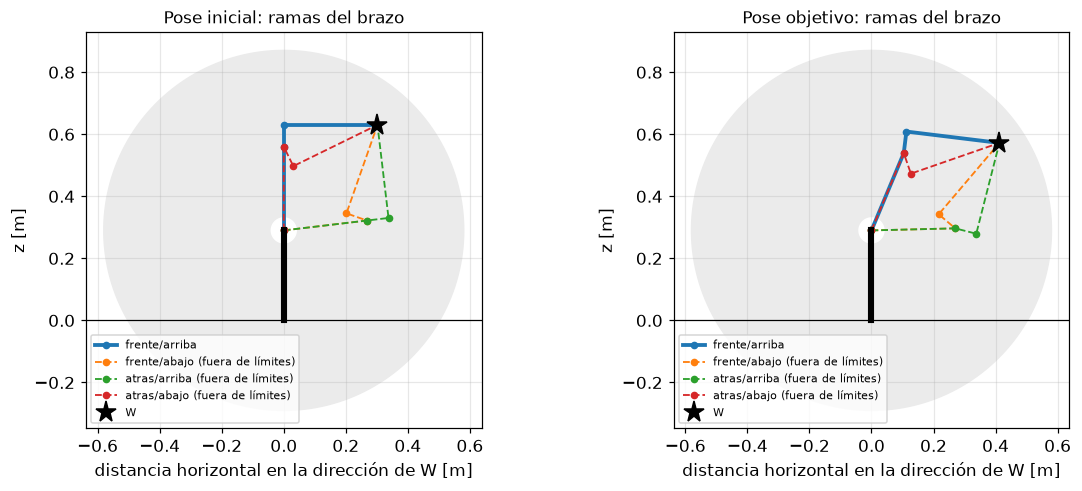

In [7]:
def arm_points(candidate, u):
    # Orígenes DH reales o1 (hombro), o2 (codo), o3 (desfase a3) y o4 = W, proyectados en el plano (u, z).
    frames = joint_frames(np.array(candidate.q_raw))
    pts = [frames[k][:3, 3] for k in (1, 2, 3, 4)]
    return np.array([[p[:2] @ u, p[2]] for p in pts])

def plot_arm_branches(name, ax):
    report = REPORTS[name]
    W = report.wrist_center
    u = W[:2] / np.linalg.norm(W[:2])        # dirección horizontal hacia W
    S = np.array([0.0, D1])
    th = np.linspace(0, 2 * np.pi, 200)
    ax.fill(S[0] + REACH_MAX_M * np.cos(th), S[1] + REACH_MAX_M * np.sin(th), color="0.92", zorder=0)
    ax.fill(S[0] + REACH_MIN_M * np.cos(th), S[1] + REACH_MIN_M * np.sin(th), color="white", zorder=0)
    styles = {("frente", "arriba"): "C0", ("frente", "abajo"): "C1", ("atras", "arriba"): "C2", ("atras", "abajo"): "C3"}
    for c in report.candidates:
        if c.wrist != "q5-" or not c.real:
            continue  # la muñeca no cambia el brazo: una línea por rama de brazo
        pts = arm_points(c, u)
        admissible_arm = any(report.accepted(o) for o in report.candidates
                             if (o.arm, o.elbow) == (c.arm, c.elbow))
        ax.plot(pts[:, 0], pts[:, 1], "-o", color=styles[(c.arm, c.elbow)], lw=2.5 if admissible_arm else 1.2,
                ls="-" if admissible_arm else "--", ms=4,
                label=f"{c.arm}/{c.elbow}" + ("" if admissible_arm else " (fuera de límites)"))
    ax.plot([0, 0], [0, D1], "k", lw=4)      # columna de la base hasta el hombro
    ax.plot(np.hypot(W[0], W[1]), W[2], "k*", ms=14, label="W")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_aspect("equal"); ax.set_xlabel("distancia horizontal en la dirección de W [m]"); ax.set_ylabel("z [m]")
    ax.set_title(f"Pose {name.lower()}: ramas del brazo"); ax.legend(loc="lower left", fontsize=7)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
plot_arm_branches("Inicial", axes[0])
plot_arm_branches("Objetivo", axes[1])
fig.tight_layout(); save(fig, "A_ramas_brazo"); plt.show()

En la pose inicial solo la rama frente/arriba es admisible. Las demás llevan $q_2$ o $q_3$ fuera de rango, o
$q_1 = 180°$ (más allá de ±165°). En la pose objetivo, la tabla de la sección anterior indica qué junta bloquea cada
rama.

### 2.2 Las 8 configuraciones del robot para la pose objetivo

Cada panel dibuja el robot completo (base → hombro → codo → desfase $a_3$ → muñeca → brida → TCP) en una de las
8 ramas. Todas las ramas **reales** llevan el TCP al mismo punto con la misma orientación: el triedro del TCP
(x rojo, y verde, z azul) coincide con el triedro objetivo, dibujado con línea discontinua. Lo que cambia es *cómo*
llega el brazo.

- **Verde:** la rama elegida con el criterio de la sección 4.
- **Azul:** admisible, pero no elegida.
- **Rojo discontinuo:** existe geométricamente pero viola límites. Se dibuja con sus ángulos crudos: el robot real
  **no** podría adoptarla.
- **Rama no real:** el panel lo indica, porque no existe ninguna postura.

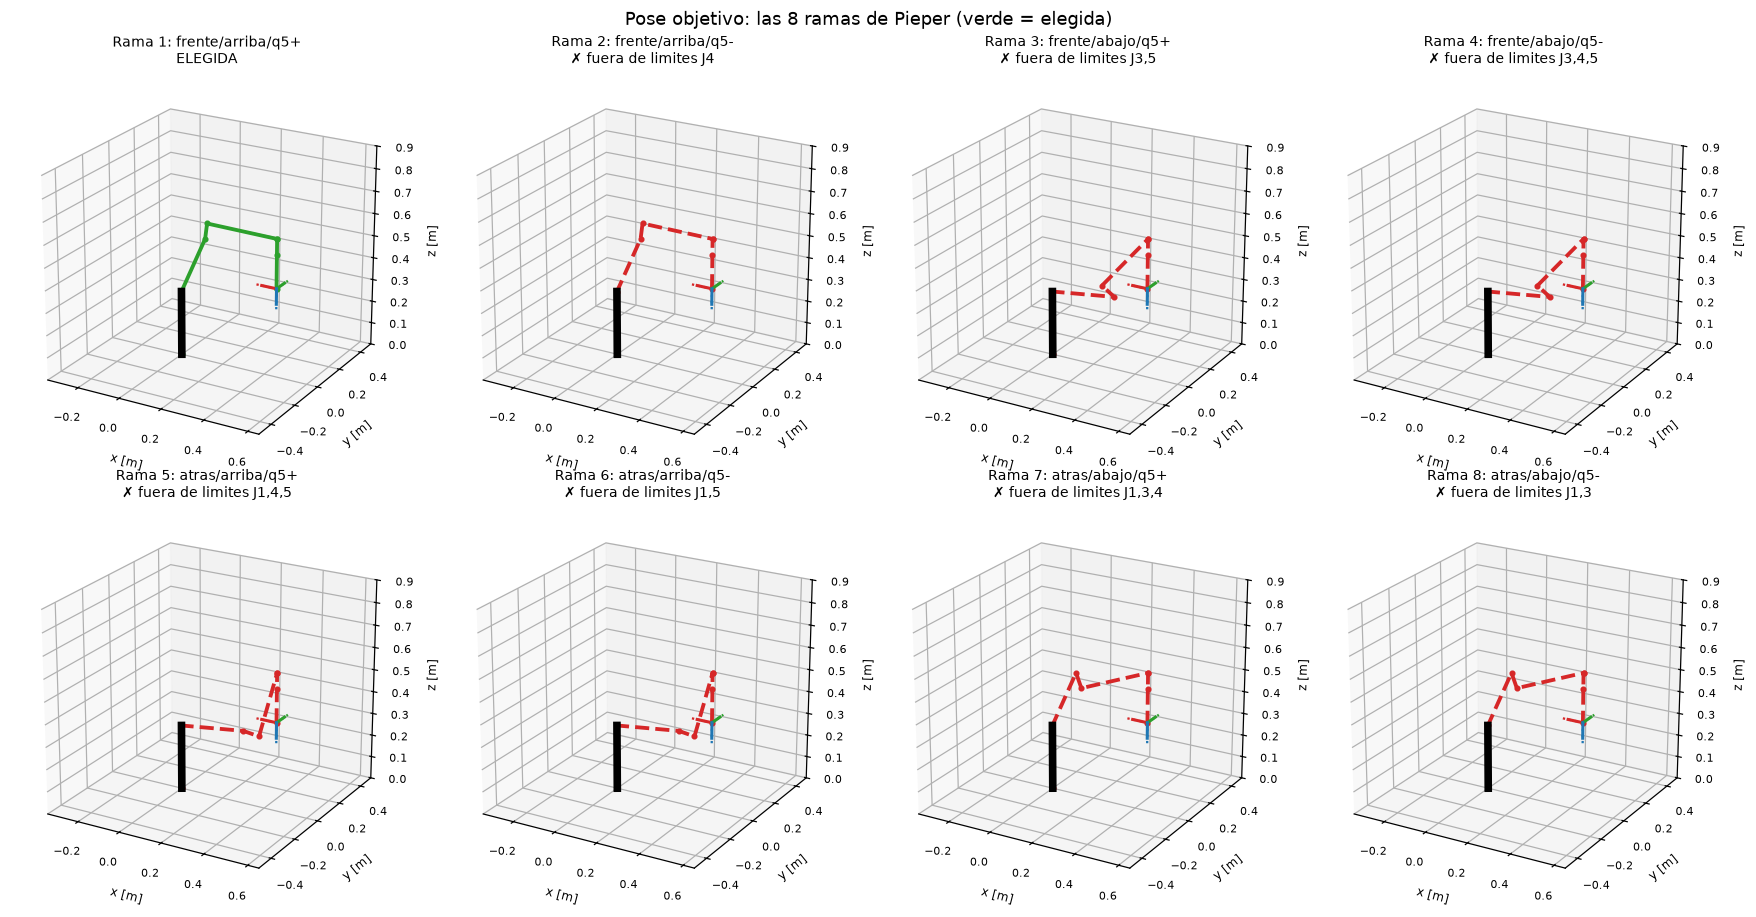

In [8]:
DECISIONS = rank_candidates(REPORTS["Objetivo"], Q_HOME)
fig = plt.figure(figsize=(16, 8.4))
for k, dec in enumerate(DECISIONS):
    c = dec.candidate
    ax = fig.add_subplot(2, 4, k + 1, projection="3d")
    head = f"Rama {c.branch}: {c.arm}/{c.elbow}/{c.wrist}"
    if not c.real:
        setup_3d(ax, head + "\nNO EXISTE (|c| > 1)"); continue
    q_draw = np.array(c.q if c.q is not None else c.q_raw)
    color, ls = (("tab:green", "-") if dec.rank == 1 else ("tab:blue", "-") if dec.admissible else ("tab:red", "--"))
    draw_robot(ax, q_draw, color, ls=ls)
    draw_frame(ax, T_D, length=0.10, ls=":", lw=1.5)                       # objetivo
    draw_frame(ax, forward_kinematics_tcp(q_draw), length=0.07)            # TCP alcanzado
    ax.plot([0, 0], [0, 0], [0, D1], color="k", lw=5)
    setup_3d(ax, head + "\n" + dec.status.replace("descartada: ", "✗ "))
fig.suptitle("Pose objetivo: las 8 ramas de Pieper (verde = elegida)", fontsize=12)
fig.tight_layout(); save(fig, "A_ocho_ramas_3d"); plt.show()

## 3. Validación sistemática por cinemática directa (criterio B)

Cada rama **real** de las dos poses se reinyecta en la FK, incluso las que violan límites, y se compara la pose
**completa**:

$$
e_p = \lVert p(q^{(k)}) - p_d\rVert\ [\text{m}], \qquad
e_R = \angle\big(R_d^T R(q^{(k)})\big)\ [\text{rad}], \qquad
\textbf{acepta si } e_p < 10^{-6}\ \text{m y } e_R < 10^{-6}\ \text{rad}
$$

La tolerancia de $10^{-6}$ es 10 veces menor que la repetibilidad del IRB 120 (0.01 mm) y 10⁹ veces mayor que el
redondeo de punto flotante. Una rama correcta da errores del orden de $10^{-16}$; un error de signo en la deducción
daría del orden de $10^{-2}$ y quedaría **detectado como inconsistencia**.

    pose  k    e_p [m]  e_R [rad]  ||T-Td||_F  acepta
 Inicial  1   2.22e-16   4.44e-16    6.66e-16  sí
 Inicial  2   2.22e-16   5.07e-16    7.51e-16  sí
 Inicial  3   1.57e-16   4.40e-17    1.69e-16  sí
 Inicial  4   1.57e-16   5.86e-17    1.78e-16  sí
 Inicial  5   4.50e-17   2.84e-17    1.68e-16  sí
 Inicial  6   2.64e-17   7.17e-17    1.89e-16  sí
 Inicial  7   3.24e-17   1.87e-16    3.47e-16  sí
 Inicial  8   4.03e-17   3.90e-17    2.32e-16  sí
Objetivo  1   7.85e-17   1.99e-16    3.14e-16  sí
Objetivo  2   6.21e-17   1.95e-16    3.04e-16  sí
Objetivo  3   1.42e-16   2.65e-16    4.18e-16  sí
Objetivo  4   1.25e-16   2.58e-16    4.07e-16  sí
Objetivo  5   1.24e-16   2.06e-16    3.36e-16  sí
Objetivo  6   7.85e-17   1.88e-16    3.01e-16  sí
Objetivo  7   1.67e-16   2.72e-16    4.36e-16  sí
Objetivo  8   1.31e-16   1.38e-16    2.63e-16  sí


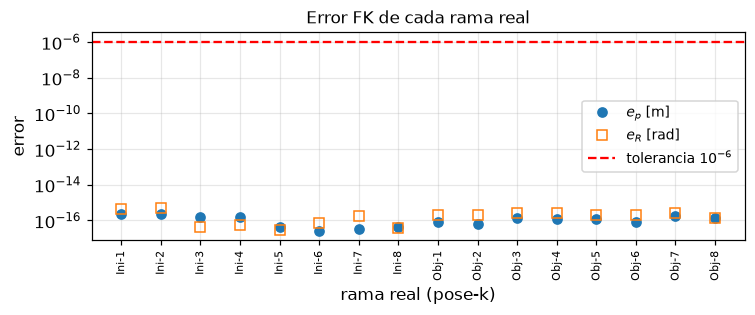


Verificaciones de la etapa B:
  ✔ [B] las 16 ramas reales reproducen su pose (posición y orientación) bajo tolerancia


In [9]:
rows = []
for name, report in REPORTS.items():
    for c, chk in zip(report.candidates, report.checks):
        if chk is not None:
            rows.append((name, c.branch, chk.position_error_m, chk.rotation_error_rad, chk.frobenius_error, chk.accepted))
print(f"{'pose':>8} {'k':>2} {'e_p [m]':>10} {'e_R [rad]':>10} {'||T-Td||_F':>11}  acepta")
for r in rows:
    print(f"{r[0]:>8} {r[1]:>2} {r[2]:10.2e} {r[3]:10.2e} {r[4]:11.2e}  {'sí' if r[5] else 'NO'}")

ep = np.array([r[2] for r in rows]); er = np.array([r[3] for r in rows])
labels = [f"{r[0][:3]}-{r[1]}" for r in rows]
fig, ax = plt.subplots(figsize=(7, 3))
ax.semilogy(ep + 1e-20, "o", label="$e_p$ [m]"); ax.semilogy(er + 1e-20, "s", mfc="none", label="$e_R$ [rad]")
ax.axhline(POSITION_TOL_M, color="r", ls="--", label="tolerancia $10^{-6}$")
ax.set_xticks(range(len(rows)), labels, rotation=90, fontsize=7)
ax.set_xlabel("rama real (pose-k)"); ax.set_ylabel("error"); ax.legend()
ax.set_title("Error FK de cada rama real")
fig.tight_layout(); save(fig, "B_errores_fk"); plt.show()

print("\nVerificaciones de la etapa B:")
check("B", f"las {len(rows)} ramas reales reproducen su pose (posición y orientación) bajo tolerancia",
      all(r[5] for r in rows))

**¿El criterio detecta errores de verdad?** Se fabrican dos candidatos erróneos a partir de la solución
admisible de la pose objetivo: uno con 1 mrad de error en $q_1$ y otro donde solo se gira $q_6$ en 0.01 rad. El
segundo **no mueve el TCP**, porque $q_6$ gira sobre su propio eje: comparar solo la posición lo aceptaría.
Comparar también la orientación lo rechaza.

In [10]:
q_ok = np.array(REPORTS["Objetivo"].admissible[0].q)
for label, dq in (("error en q1 = 1e-3 rad", [1e-3, 0, 0, 0, 0, 0]), ("error solo en q6 = 1e-2 rad", [0, 0, 0, 0, 0, 1e-2])):
    chk = fk_check(T_D, q_ok + np.array(dq))
    print(f"{label:28s}: e_p = {chk.position_error_m:.2e} m, e_R = {chk.rotation_error_rad:.2e} rad -> "
          f"{'acepta' if chk.accepted else 'RECHAZA'}")
    check("B", f"se rechaza el candidato con {label}", not chk.accepted)

stats = round_trip_test(samples=1000, seed=0)
print(f"\nIda y vuelta con {stats.samples} q aleatorios en límites: resueltas {stats.solved}, "
      f"q original recuperado {stats.recovered_original}, peor e_p = {stats.max_position_error_m:.1e} m, "
      f"peor e_R = {stats.max_rotation_error_rad:.1e} rad")
check("B", "ida y vuelta: 1000/1000 poses resueltas y q original recuperado",
      stats.solved == stats.recovered_original == stats.samples)

error en q1 = 1e-3 rad      : e_p = 4.12e-04 m, e_R = 1.00e-03 rad -> RECHAZA
  ✔ [B] se rechaza el candidato con error en q1 = 1e-3 rad
error solo en q6 = 1e-2 rad : e_p = 7.85e-17 m, e_R = 1.00e-02 rad -> RECHAZA
  ✔ [B] se rechaza el candidato con error solo en q6 = 1e-2 rad



Ida y vuelta con 1000 q aleatorios en límites: resueltas 1000, q original recuperado 1000, peor e_p = 5.8e-16 m, peor e_R = 4.0e-13 rad
  ✔ [B] ida y vuelta: 1000/1000 poses resueltas y q original recuperado


### 3.1 ¿Y si la propia FK estuviera mal? Dos verificaciones externas

La validación anterior usa nuestra FK como "patrón". Para comprobar el patrón:

| Verificación | Contra qué | Qué demuestra |
|---|---|---|
| **Geométrica (independiente)** | Modelo **oficial de ROS-Industrial** (`abb_irb120_support`, `irb120/rosi_model.py`): traslaciones y ejes tomados de los planos de ABB, sin parámetros DH | Que la **tabla DH** describe el robot real: cotas, ejes, signos y offsets. Es otra fuente y otra convención |
| **De implementación** | URDF del Hito 1 (`datos/irb120.urdf`), evaluado con `irb120/urdf_chain.py` | Que el **código** (matrices DH frente a origins y ejes) es correcto. **No** es una fuente geométrica independiente, porque ese URDF se derivó de la misma tabla DH |

In [11]:
from irb120.rosi_model import rosi_forward_kinematics, SOURCE_URL
URDF_PATH = ROOT / "datos" / "irb120.urdf"
def urdf_fk(q):
    return chain_transform(URDF_PATH, {f"joint_{i + 1}": q[i] for i in range(6)})   # base_link -> tool0

rng = np.random.default_rng(1)
samples = [Q_HOME, np.array(REPORTS["Objetivo"].admissible[0].q)] + \
          [rng.uniform(np.deg2rad(JOINT_LIMITS_DEG[:, 0]), np.deg2rad(JOINT_LIMITS_DEG[:, 1])) for _ in range(300)]
d_rosi = np.array([np.abs(forward_kinematics(q) - rosi_forward_kinematics(q)).max() for q in samples])
d_urdf = np.array([np.abs(forward_kinematics(q) - urdf_fk(q)).max() for q in samples])
print(f"Modelo oficial ROS-Industrial ({SOURCE_URL.split('/')[-1]}):")
print(f"  max |T_DH - T_ROS-I| en {len(samples)} configuraciones (home, q_f y 300 aleatorias) = {d_rosi.max():.1e}")
print(f"URDF del Hito 1 (derivado de DH, verifica el código): max |T_DH - T_URDF| = {d_urdf.max():.1e}")
check("B", "la FK por DH coincide con el modelo OFICIAL de ROS-Industrial (pose completa, < 1e-9)", d_rosi.max() < 1e-9)
check("B", "la FK por DH coincide con el URDF del Hito 1 (implementación, < 1e-9)", d_urdf.max() < 1e-9)

Modelo oficial ROS-Industrial (irb120_3_58_macro.xacro):
  max |T_DH - T_ROS-I| en 302 configuraciones (home, q_f y 300 aleatorias) = 1.2e-15
URDF del Hito 1 (derivado de DH, verifica el código): max |T_DH - T_URDF| = 1.1e-15
  ✔ [B] la FK por DH coincide con el modelo OFICIAL de ROS-Industrial (pose completa, < 1e-9)
  ✔ [B] la FK por DH coincide con el URDF del Hito 1 (implementación, < 1e-9)


## 4. Selección de la configuración objetivo: de 8 ramas a 1

Se muestran **las 8 ramas** con sus métricas y se elige **una** con este criterio, aplicado en orden:

| Paso | Regla | Por qué |
|---|---|---|
| 1 | **Admisible**: real, dentro de límites y verificada por FK | Obligatorio. Una rama fuera de límites no la puede ejecutar el robot real; una rama que no pasa la FK no es solución |
| 2 | **Lejos de singularidad**: $\sigma_{\min}(J) \ge 0.01$ | Como $\lVert\dot q\rVert \le \lVert\dot x\rVert/\sigma_{\min}$, con $\sigma_{\min} \ge 0.01$ la amplificación queda acotada a 100×. Terminar cerca de una singularidad haría que cualquier corrección o movimiento siguiente exija velocidades enormes (sección 7) |
| 3 | **Lejos de los topes**: margen $\ge 5°$ en las 6 juntas | El controlador real aplica límites de software y el seguimiento tiene error. Una postura pegada a un tope deja sin margen para corregir o para continuar hacia otra pose |
| 4 | **Menor desplazamiento ponderado** $\lVert W(q - q_0)\rVert$, con $W = \operatorname{diag}(1,1,1,\tfrac12,\tfrac12,\tfrac12)$; desempate por mayor $\sigma_{\min}$ | Menor recorrido significa menos tiempo, menos energía y menos volumen barrido (menor riesgo de colisión). Además evita "voltear" el brazo o la muñeca. Las juntas 1 a 3 mueven unos 12 kg y la muñeca menos de 3 kg (sección 8): por eso pesan el doble |

**¿Por qué no elegir la rama de menor $t_f$?** El tiempo del LSPB lo fija una sola junta (con frecuencia la muñeca) y
depende del supuesto de $a_{\max}$. Se informa como dato de control, pero no decide. Si ninguna rama admisible
cumpliera los pasos 2 y 3, se relajan en ese orden (primero el margen, después $\sigma_{\min}$) y la tabla lo indica.
Con la pose inicial en $q_0$ (el robot está físicamente ahí, y la sección 2 comprobó que Pieper la recupera), el
resultado es $q_f$.

In [12]:
print(f"{'k':>2} {'rama':>20} {'adm.':>5} {'σ_min(J)':>9} {'margen [°]':>10} {'||W(q-q0)||':>12} {'t_f LSPB [s]':>12}  decisión")
for d in DECISIONS:
    c = d.candidate
    num = (f"{d.sigma_min:9.4f} {d.limit_margin_deg:10.1f} {d.weighted_cost:12.4f} {d.lspb_tf:12.4f}"
           if d.admissible else f"{'—':>9} {'—':>10} {'—':>12} {'—':>12}")
    print(f"{c.branch:>2} {c.arm + '/' + c.elbow + '/' + c.wrist:>20} {'sí' if d.admissible else 'no':>5} {num}  {d.status}")

chosen = select_solution(REPORTS["Objetivo"], Q_HOME)
best = next(d for d in DECISIONS if d.rank == 1)
Q0, QF = Q_HOME.copy(), np.array(chosen.q)
print(f"\nq0 (pose inicial)  = {deg(Q0).round(3)} deg")
print(f"qf (pose objetivo) = {deg(QF).round(3)} deg   (rama {chosen.branch}: {chosen.arm}/{chosen.elbow}/{chosen.wrist})")
print(f"Justificación: admisible, σ_min = {best.sigma_min:.3f} ≥ 0.01, margen a límites = {best.limit_margin_deg:.1f}° ≥ 5°, "
      f"y menor desplazamiento ponderado ({best.weighted_cost:.3f}) entre las aptas.")
check("A", "se evaluaron las 8 ramas y se eligió exactamente una", len(DECISIONS) == 8 and sum(d.rank == 1 for d in DECISIONS) == 1)
check("A", "la configuración elegida es admisible y reproduce T_d", fk_check(T_D, QF).accepted)

 k                 rama  adm.  σ_min(J) margen [°]  ||W(q-q0)|| t_f LSPB [s]  decisión
 1    frente/arriba/q5+    sí    0.1167       37.0       0.9120       1.2879  ELEGIDA
 2    frente/arriba/q5-    no         —          —            —            —  descartada: fuera de limites J4
 3     frente/abajo/q5+    no         —          —            —            —  descartada: fuera de limites J3,5
 4     frente/abajo/q5-    no         —          —            —            —  descartada: fuera de limites J3,4,5
 5     atras/arriba/q5+    no         —          —            —            —  descartada: fuera de limites J1,4,5
 6     atras/arriba/q5-    no         —          —            —            —  descartada: fuera de limites J1,5
 7      atras/abajo/q5+    no         —          —            —            —  descartada: fuera de limites J1,3,4
 8      atras/abajo/q5-    no         —          —            —            —  descartada: fuera de limites J1,3

q0 (pose inicial)  = [0. 0. 0. 0. 0. 0

## 5. Trayectoria LSPB de la pose inicial a la pose objetivo (criterio C)

Un LSPB **sincronizado** de $q_0$ a $q_f$: todas las juntas comparten $t_f$ y $t_b$, parten y llegan en reposo.

$$
q(t) = \begin{cases}
q_0 + \tfrac12 a t^2 & 0 \le t < t_b\\
q_0 + V\,(t - \tfrac{t_b}{2}) & t_b \le t \le t_f - t_b\\
q_f - \tfrac12 a (t_f - t)^2 & t_f - t_b < t \le t_f
\end{cases}
\qquad V = \frac{q_f - q_0}{t_f - t_b},\quad a = \frac{V}{t_b}
$$

**Parámetros justificados:**

- $v_{\max,i} = 0.25 \times v_{\text{datasheet},i}$: factor de velocidad del 25 %, conservador para laboratorio.
- $a_{\max,i} = v_{\max,i}/0.25$ s: **supuesto declarado**, porque ABB no publica aceleraciones articulares.

Se busca el $t_f$ **mínimo** que cumple $|V_i| \le v_{\max,i}$ y $|a_i| \le a_{\max,i}$ en las 6 juntas, por bisección
(la factibilidad es monótona en $t_f$). Si la misma junta satura los dos límites, la solución es cerrada:
$t_b = v_{\max}/a_{\max}$ y $t_f = D/v_{\max} + t_b$.

In [13]:
VMAX, AMAX = default_limits(SPEED_SCALE, RAMP_TIME_S)
TRAJ = plan_lspb(Q0, QF, VMAX, AMAX)
D = QF - Q0
TRIANGULAR = TRAJ.tf - 2 * TRAJ.tb < 1e-6
print(f"t_f = {TRAJ.tf:.4f} s,   t_b = {TRAJ.tb:.4f} s,   crucero = {TRAJ.tf - 2 * TRAJ.tb:.4f} s"
      + ("   -> perfil TRIANGULAR (movimiento corto: no alcanza la velocidad de crucero máxima)" if TRIANGULAR else "") + "\n")
print(f"{'junta':>5} {'D [deg]':>9} {'V [deg/s]':>10} {'a [deg/s2]':>11} {'|V|/vmax':>9} {'|a|/amax':>9}")
for j in range(6):
    print(f"{j+1:>5} {deg(D[j]):9.3f} {deg(TRAJ.cruise_velocity[j]):10.3f} {deg(TRAJ.blend_acceleration[j]):11.3f} "
          f"{abs(TRAJ.cruise_velocity[j]) / VMAX[j]:9.3f} {abs(TRAJ.blend_acceleration[j]) / AMAX[j]:9.3f}")
critical = int(np.argmax(np.maximum(np.abs(D) / VMAX, np.abs(D) / AMAX))) + 1
print(f"\nJunta crítica (fija t_f): J{critical}")

LCHK = check_trajectory(TRAJ, VMAX, AMAX)
print("\nVerificaciones de la etapa C:")
check("C", f"q(0) = q0 y q(tf) = qf (error {max(LCHK.start_position_error, LCHK.end_position_error):.1e})",
      max(LCHK.start_position_error, LCHK.end_position_error) < 1e-9)
check("C", "reposo en las fronteras: q̇(0) = q̇(tf) = 0", max(LCHK.start_velocity, LCHK.end_velocity) < 1e-12)
check("C", f"q y q̇ continuas en t_b y t_f - t_b (saltos {LCHK.position_jump:.1e}, {LCHK.velocity_jump:.1e})",
      max(LCHK.position_jump, LCHK.velocity_jump) < 1e-6)
check("C", "se respetan vmax y amax en las 6 juntas", min(LCHK.velocity_margin, LCHK.acceleration_margin) > -1e-9)
check("C", "t_b ≤ t_f/2 (existe el perfil LSPB)", TRAJ.tb <= TRAJ.tf / 2 + 1e-12)

t_f = 1.2879 s,   t_b = 0.2500 s,   crucero = 0.7879 s

junta   D [deg]  V [deg/s]  a [deg/s2]  |V|/vmax  |a|/amax
    1    14.036     13.523      54.094     0.216     0.216
    2    22.667     21.839      87.354     0.349     0.349
    3   -15.700    -15.127     -60.507     0.242     0.242
    4    -0.000     -0.000      -0.000     0.000     0.000
    5    83.034     80.000     320.000     1.000     1.000
    6    14.036     13.523      54.094     0.129     0.129

Junta crítica (fija t_f): J5

Verificaciones de la etapa C:
  ✔ [C] q(0) = q0 y q(tf) = qf (error 0.0e+00)
  ✔ [C] reposo en las fronteras: q̇(0) = q̇(tf) = 0
  ✔ [C] q y q̇ continuas en t_b y t_f - t_b (saltos 2.8e-09, 5.6e-09)
  ✔ [C] se respetan vmax y amax en las 6 juntas
  ✔ [C] t_b ≤ t_f/2 (existe el perfil LSPB)


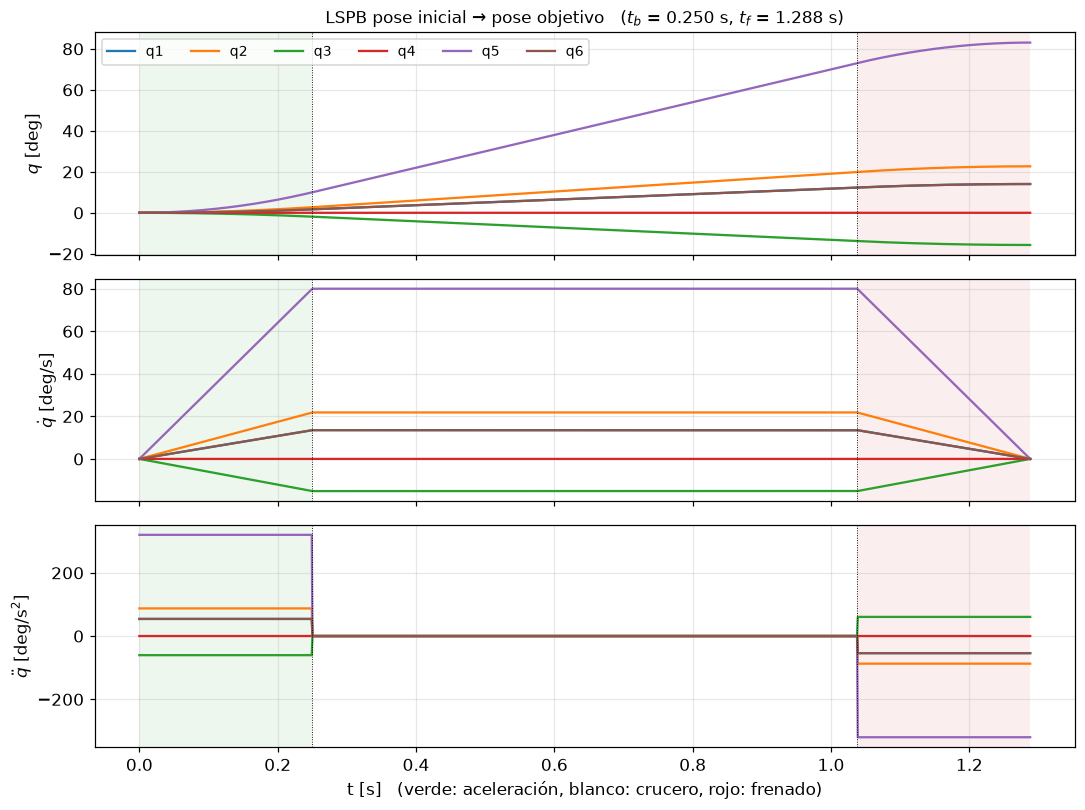

In [14]:
T_GRID = np.linspace(0.0, TRAJ.tf, 1200)
Q_T, QD_T, QDD_T = TRAJ.sample_many(T_GRID)

def mark_phases(ax):
    ax.axvspan(0, TRAJ.tb, color="tab:green", alpha=0.08, lw=0)
    ax.axvspan(TRAJ.tf - TRAJ.tb, TRAJ.tf, color="tab:red", alpha=0.08, lw=0)
    for t in (TRAJ.tb, TRAJ.tf - TRAJ.tb):
        ax.axvline(t, color="k", lw=0.6, ls=":")

fig, axes = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)
for j in range(6):
    axes[0].plot(T_GRID, deg(Q_T[:, j]), color=JOINT_COLORS[j], label=f"q{j+1}")
    axes[1].plot(T_GRID, deg(QD_T[:, j]), color=JOINT_COLORS[j])
    axes[2].plot(T_GRID, deg(QDD_T[:, j]), color=JOINT_COLORS[j])
for ax, lab in zip(axes, ("$q$ [deg]", r"$\dot q$ [deg/s]", r"$\ddot q$ [deg/s$^2$]")):
    mark_phases(ax); ax.set_ylabel(lab)
axes[0].legend(ncol=6, loc="upper left")
axes[0].set_title(f"LSPB pose inicial → pose objetivo   ($t_b$ = {TRAJ.tb:.3f} s, $t_f$ = {TRAJ.tf:.3f} s)")
axes[2].set_xlabel("t [s]   (verde: aceleración, blanco: crucero, rojo: frenado)")
fig.tight_layout(); save(fig, "C_lspb_perfiles"); plt.show()

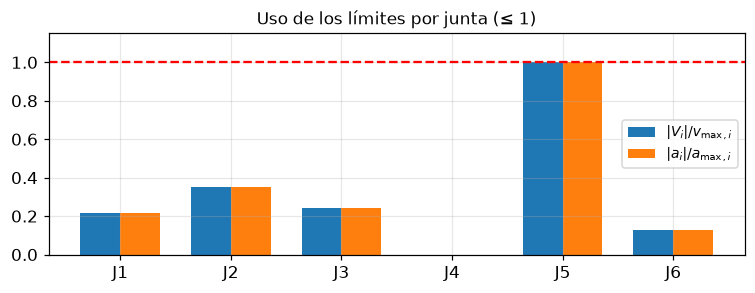

In [15]:
fig, ax = plt.subplots(figsize=(7, 2.8))
x = np.arange(1, 7)
ax.bar(x - 0.18, np.abs(TRAJ.cruise_velocity) / VMAX, 0.36, label=r"$|V_i|/v_{\max,i}$")
ax.bar(x + 0.18, np.abs(TRAJ.blend_acceleration) / AMAX, 0.36, label=r"$|a_i|/a_{\max,i}$")
ax.axhline(1, color="r", ls="--"); ax.set_xticks(x, [f"J{i}" for i in x]); ax.set_ylim(0, 1.15); ax.legend()
ax.set_title("Uso de los límites por junta (≤ 1)")
fig.tight_layout(); save(fig, "C_uso_limites"); plt.show()

**Interpretación.**

- $q(t)$ tiene forma de "S": las parábolas evitan arrancar y frenar en seco. $\dot q(t)$ es un trapecio (o un
  triángulo si el movimiento es tan corto que $t_b = t_f/2$) y $\ddot q(t)$ son escalones $+a$, $0$, $-a$.
- Todas las juntas empiezan y terminan a la vez (sincronía) y en reposo. $q$ y $\dot q$ son continuas; $\ddot q$ no
  (el LSPB es $C^1$), y eso aparece como escalones en el torque inercial (sección 8).
- La **junta crítica** llega a su límite ($|V|/v_{\max} = 1$ y/o $|a|/a_{\max} = 1$) y fija $t_f$. Las demás van más
  lentas para llegar a la vez.

### 5.1 El movimiento en el espacio de trabajo

El robot en la **pose inicial** (gris) y en la **pose objetivo** (verde), varias posturas intermedias del LSPB y
la **trayectoria del TCP** (negro). El LSPB es **articular**, así que el TCP no va en línea recta: describe la curva
que resulta de mover las 6 juntas de forma sincronizada. El triedro discontinuo es la pose pedida $T_d$; el TCP final
coincide con él.

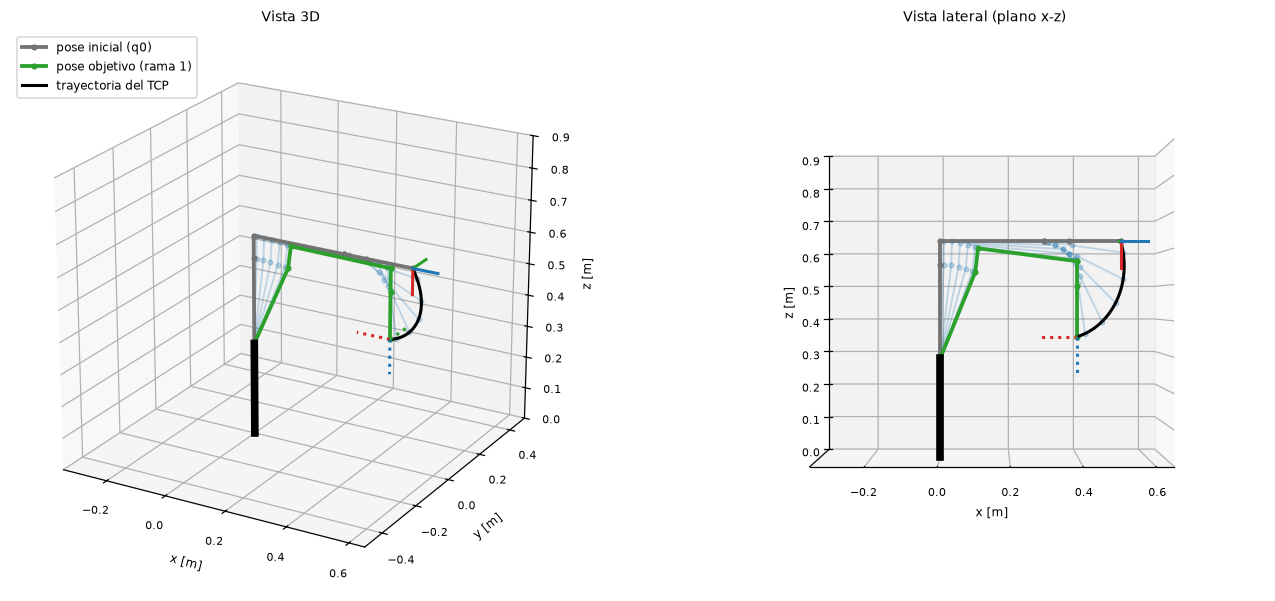

El TCP recorre 0.354 m (distancia en línea recta: 0.322 m).


In [16]:
fig = plt.figure(figsize=(13, 5.6))
P_TCP = np.array([forward_kinematics_tcp(q)[:3, 3] for q in Q_T])
for idx, (elev, azim, title) in enumerate(((22, -60, "Vista 3D"), (0, -90, "Vista lateral (plano x-z)"))):
    ax = fig.add_subplot(1, 2, idx + 1, projection="3d")
    for t in np.linspace(0, TRAJ.tf, 7)[1:-1]:
        draw_robot(ax, TRAJ.sample(t)[0], "tab:blue", lw=1.2, alpha=0.25)
    draw_robot(ax, Q0, "0.45", label="pose inicial (q0)")
    draw_robot(ax, QF, "tab:green", label=f"pose objetivo (rama {chosen.branch})")
    ax.plot(P_TCP[:, 0], P_TCP[:, 1], P_TCP[:, 2], "k-", lw=2, label="trayectoria del TCP")
    draw_frame(ax, T_HOME, length=0.08); draw_frame(ax, T_D, length=0.11, ls=":")
    ax.plot([0, 0], [0, 0], [0, D1], color="k", lw=5)
    setup_3d(ax, title); ax.view_init(elev=elev, azim=azim)
    if idx == 0: ax.legend(loc="upper left", fontsize=8)
    else: ax.set_yticks([]); ax.set_ylabel("")
fig.tight_layout(); save(fig, "C_movimiento_3d"); plt.show()
print(f"El TCP recorre {np.sum(np.linalg.norm(np.diff(P_TCP, axis=0), axis=1)):.3f} m "
      f"(distancia en línea recta: {np.linalg.norm(T_D[:3, 3] - T_HOME[:3, 3]):.3f} m).")

## 6. Jacobiano geométrico $\dot x = J(q)\,\dot q$ (criterio D, primera parte)

Columna $i$ para una junta de revolución, con el TCP como punto de referencia:

$$
J_i = \begin{bmatrix} z_{i-1}\times(p_{TCP} - o_{i-1})\\ z_{i-1}\end{bmatrix}
$$

**Validaciones:**

1. Contra derivadas numéricas centrales de la FK, que son independientes de la fórmula: $[\omega]_\times = \dot R R^T$.
2. Una columna calculada **a mano** en $q = 0$ (pose inicial).
3. Sobre la trayectoria: $v(t) = J_v\dot q$ comparada con la derivada numérica de $p(q(t))$.

In [17]:
J = geometric_jacobian(QF)
diff = np.abs(J - numerical_jacobian(QF)).max()
print("J(q_f) =\n", J)
print(f"max |J - J_numérico| = {diff:.2e}")

J0 = geometric_jacobian(Q0)
print("\nColumnas en la pose inicial q = 0 (comparar con explicacion/05):")
for i in range(6):
    print(f"  J{i+1} = v {J0[:3, i].round(3)}  ω {J0[3:, i].round(3)}")
print("\nVerificaciones de la etapa D (Jacobiano):")
check("D", "J analítico = J por diferencias finitas de la FK (< 1e-8)", diff < 1e-8)
check("D", "columna 1 en q = 0 hecha a mano: (0, 0.524, 0 | 0, 0, 1)",
      np.allclose(J0[:, 0], [0, 0.524, 0, 0, 0, 1], atol=1e-12))
check("D", "columna 2 en q = 0 hecha a mano: (0.340, 0, -0.524 | 0, 1, 0)",
      np.allclose(J0[:, 1], [0.340, 0, -0.524, 0, 1, 0], atol=1e-12))
print("  rango J en la pose inicial:", rank_analysis(J0).rank, "  (columnas 4 y 6 iguales: q5 = 0)")
print("  rango J en la pose objetivo:", rank_analysis(J).rank)

print("\nInterpretación de columnas en q_f: brazo de palanca ||J_v,i|| [m por rad] y eje z_{i-1}")
for i in range(6):
    print(f"  junta {i+1}: ||J_v|| = {np.linalg.norm(J[:3, i]):.3f} m/rad,  z = {J[3:, i].round(3)}")

J(q_f) =
 [[-0.1     0.0582 -0.1835 -0.0534 -0.2154 -0.    ]
 [ 0.4     0.0146 -0.0459  0.2138 -0.0538 -0.    ]
 [ 0.     -0.4123 -0.3083  0.     -0.     -0.    ]
 [ 0.     -0.2425 -0.2425  0.963  -0.2425 -0.    ]
 [ 0.      0.9701  0.9701  0.2407  0.9701  0.    ]
 [ 1.      0.      0.     -0.1213 -0.     -1.    ]]
max |J - J_numérico| = 1.40e-10

Columnas en la pose inicial q = 0 (comparar con explicacion/05):
  J1 = v [-0.     0.524  0.   ]  ω [0. 0. 1.]
  J2 = v [ 0.34   0.    -0.524]  ω [0. 1. 0.]
  J3 = v [ 0.07   0.    -0.524]  ω [0. 1. 0.]
  J4 = v [ 0. -0. -0.]  ω [ 1.  0. -0.]
  J5 = v [-0.     0.    -0.222]  ω [0. 1. 0.]
  J6 = v [ 0. -0. -0.]  ω [ 1.  0. -0.]

Verificaciones de la etapa D (Jacobiano):
  ✔ [D] J analítico = J por diferencias finitas de la FK (< 1e-8)
  ✔ [D] columna 1 en q = 0 hecha a mano: (0, 0.524, 0 | 0, 0, 1)
  ✔ [D] columna 2 en q = 0 hecha a mano: (0.340, 0, -0.524 | 0, 1, 0)
  rango J en la pose inicial: 5   (columnas 4 y 6 iguales: q5 = 0)
  rango J 

**Lectura de las columnas.** $\lVert J_{v,i}\rVert$ es la distancia del TCP al eje $i$: es la velocidad lineal que
produce 1 rad/s de esa junta. Las juntas 1 a 3 tienen palancas de varios decímetros y **posicionan**. Las juntas 4 a 6
tienen palancas pequeñas (como mucho brida + TCP = 0.222 m) y sobre todo **orientan**. $J_{\omega,i} = z_{i-1}$:
cada junta aporta una rotación sobre su eje.

En la pose inicial ($q = 0$) las columnas 4 y 6 son iguales ($[0;\ (1,0,0)]$): **la posición de calibración es una
singularidad de muñeca**, porque los ejes 4 y 6 están alineados.

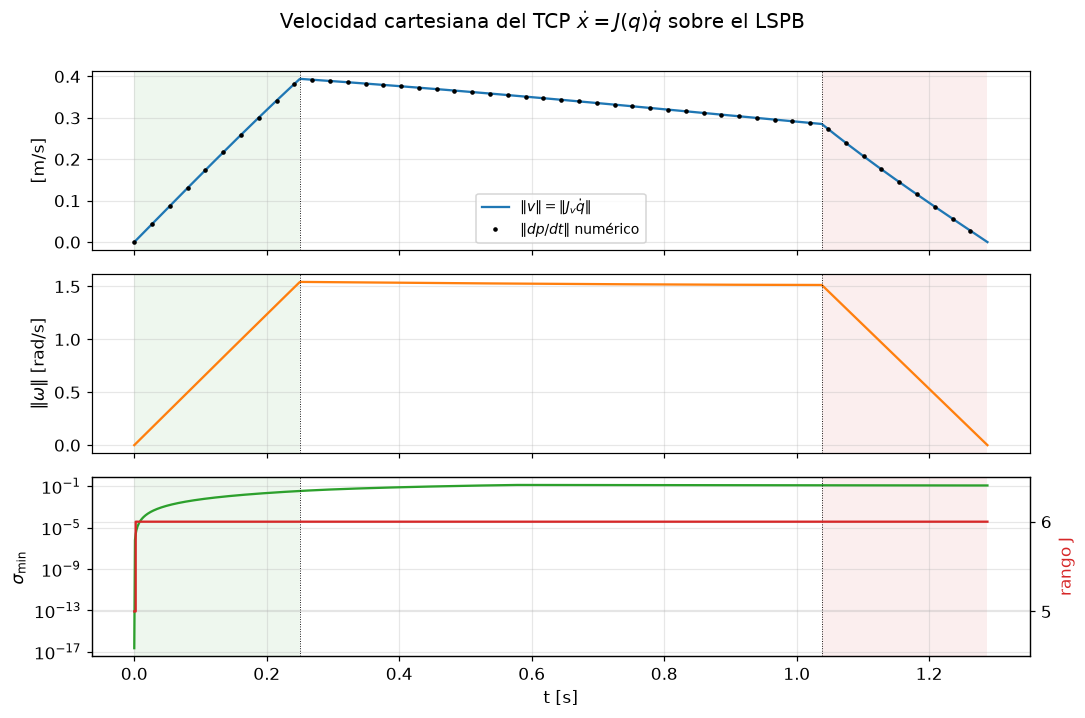

max |J_v q̇ - dp/dt| = 1.97e-10 m/s
  ✔ [D] v = J_v(q) q̇ coincide con la derivada numérica de p(q(t)) (< 1e-5 m/s)
Rango de J a lo largo de la trayectoria: mínimo 5; vale 5 en t = [0.     0.0011] s y 6 en el resto


In [18]:
TWIST_T = np.array([tcp_twist(q, qd) for q, qd in zip(Q_T, QD_T)])
H = 1e-6   # diferencia central de p(q(t)) evaluando el LSPB en t ± H
V_NUM = np.array([(forward_kinematics_tcp(TRAJ.sample(t + H)[0])[:3, 3]
                   - forward_kinematics_tcp(TRAJ.sample(t - H)[0])[:3, 3]) / (2 * H) for t in T_GRID])
SV_T = np.array([rank_analysis(geometric_jacobian(q)).singular_values for q in Q_T])
RANK_T = (SV_T > RANK_TOLERANCE).sum(axis=1)
interior = slice(2, -2)
err_v = np.abs(TWIST_T[interior, :3] - V_NUM[interior]).max()

fig, axes = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True)
axes[0].plot(T_GRID, np.linalg.norm(TWIST_T[:, :3], axis=1), label=r"$\|v\| = \|J_v \dot q\|$")
axes[0].plot(T_GRID[::25], np.linalg.norm(V_NUM, axis=1)[::25], "k.", ms=4, label=r"$\|dp/dt\|$ numérico")
axes[0].set_ylabel("[m/s]"); axes[0].legend()
axes[1].plot(T_GRID, np.linalg.norm(TWIST_T[:, 3:], axis=1), color="C1"); axes[1].set_ylabel(r"$\|\omega\|$ [rad/s]")
axes[2].semilogy(T_GRID, SV_T[:, -1] + 1e-18, color="C2", label=r"$\sigma_{\min}(J)$")
ax2 = axes[2].twinx(); ax2.step(T_GRID, RANK_T, color="C3", where="post"); ax2.set_ylim(4.5, 6.5); ax2.set_yticks([5, 6])
ax2.set_ylabel("rango J", color="C3"); axes[2].set_ylabel(r"$\sigma_{\min}$"); axes[2].set_xlabel("t [s]")
for ax in axes: mark_phases(ax)
fig.suptitle(r"Velocidad cartesiana del TCP $\dot x = J(q)\dot q$ sobre el LSPB", y=1.0)
fig.tight_layout(); save(fig, "D_twist_trayectoria"); plt.show()

print(f"max |J_v q̇ - dp/dt| = {err_v:.2e} m/s")
check("D", "v = J_v(q) q̇ coincide con la derivada numérica de p(q(t)) (< 1e-5 m/s)", err_v < 1e-5)
print(f"Rango de J a lo largo de la trayectoria: mínimo {RANK_T.min()}; vale 5 en t = "
      f"{T_GRID[RANK_T < 6].round(4)} s y 6 en el resto")

El rango baja a 5 solo al arrancar: la pose inicial tiene $q_5 = 0$ (singularidad de muñeca) y durante el primer
milisegundo $q_5$ sigue siendo tan pequeño que $\sigma_{\min} < 10^{-6}$. Si la trayectoria cambiara el signo de $q_5$,
también bajaría en el instante del cruce. **El LSPB es articular y no invierte $J$**, así que partir de la
singularidad no causa ningún problema numérico ni físico: en ese instante simplemente hay una dirección cartesiana en
la que el TCP no se puede mover. Apenas $q_5$ crece, el rango vuelve a 6. La sección 7 lo estudia en un experimento
aparte.

## 7. Experimento independiente: aproximación a la singularidad de muñeca (criterio D, segunda parte)

**Criterio central: el rango.** $q^*$ es singular si $\operatorname{rank}J(q^*) < 6$. El rango se calcula con la SVD
$J = U\Sigma V^T$ como el número de $\sigma_i > 10^{-6}$. El determinante se muestra **solo como complemento**, porque
$J$ es cuadrada: $|\det J| = \prod\sigma_i$ (el signo de $\det J$ lo dan $\det U$ y $\det V^T$). No dice cuántas
direcciones se pierden ni cuáles.

**Unidades.** $J$ mezcla filas lineales [m/s por rad/s] y angulares [rad/s por rad/s]. El **rango** no depende de
la escala elegida, pero los valores $\sigma_i$, el número de condición y la tolerancia $10^{-6}$ sí: se usan en SI,
con longitudes en metros. Del mismo modo, una "carga unitaria en $u_6$" es el vector $[F; M]$ de norma 1 con $F$ en N
y $M$ en N·m, en esa misma escala.

Factorización analítica (referencia en $W$, $J$ triangular por bloques):

$$
\det J = \underbrace{L_2L_3\cos(q_3 - \delta)\,r_W}_{\text{brazo}}\cdot\underbrace{(-\sin q_5)}_{\text{muñeca}}
$$

Así se ven las tres singularidades del IRB 120: **muñeca** ($q_5 = 0$), **codo** ($q_3 = \delta - 90°$, brazo
estirado) y **hombro** ($r_W = 0$).

**Diseño del experimento.** Se fija una postura regular $q = (30°, -20°, 15°, 40°, q_5, 60°)$ y se genera una
**secuencia de poses del TCP** $T_k = FK(q_k)$ con $q_5 \to 0$. Cada pose pasa por **el mismo pipeline**: Pieper,
FK y luego $J$.

In [19]:
Q5_SEQ_DEG = np.array([45, 30, 20, 10, 5, 3, 1, 0.3, 0.1, 0.03, 0.01, 0.0])
q_base = np.deg2rad([30.0, -20.0, 15.0, 40.0, 0.0, 60.0])
EXP = []
for q5 in Q5_SEQ_DEG:
    q_k = q_base.copy(); q_k[4] = np.deg2rad(q5)
    T_k = forward_kinematics_tcp(q_k)                       # pose del TCP de la secuencia
    rep = analyze_pose(T_k, q_k)                            # Pieper + FK sobre esa pose
    sol = select_solution(rep, q_k, min_sigma=0.0, min_margin_deg=0.0)
    q_sol = np.array(sol.q)
    Jk = geometric_jacobian(q_sol)
    ra = rank_analysis(Jk)
    EXP.append(dict(q5=q5, q=q_sol, J=Jk, ra=ra, det=np.linalg.det(Jk),
                    det_teo=-np.sin(q_sol[4]) * arm_position_determinant(q_sol),
                    singular_flag=sol.singular_wrist, fk_ok=fk_check(T_k, q_sol).accepted))

print(f"{'q5 [deg]':>9} {'rango':>5} {'sigma_1':>8} {'sigma_5':>8} {'sigma_6':>10} {'cond(J)':>10} "
      f"{'det J':>11} {'det teórico':>12}  Pieper-singular")
for e in EXP:
    s = e["ra"].singular_values
    print(f"{e['q5']:9.2f} {e['ra'].rank:>5} {s[0]:8.4f} {s[4]:8.4f} {s[5]:10.2e} {e['ra'].condition_number:10.2e} "
          f"{e['det']:11.2e} {e['det_teo']:12.2e}  {e['singular_flag']}")

print("\nVerificaciones de la etapa D (singularidad):")
check("D", "cada pose de la secuencia se resuelve por Pieper y pasa la FK", all(e["fk_ok"] for e in EXP))
check("D", "rango = 6 para q5 ≠ 0 y rango = 5 en q5 = 0",
      all(e["ra"].rank == 6 for e in EXP[:-1]) and EXP[-1]["ra"].rank == 5)
check("D", "det J coincide con la factorización -sin(q5)·det(J_brazo)",
      all(abs(e["det"] - e["det_teo"]) < 1e-10 for e in EXP))
check("D", "Pieper marca la muñeca singular en q5 = 0", EXP[-1]["singular_flag"])

 q5 [deg] rango  sigma_1  sigma_5    sigma_6    cond(J)       det J  det teórico  Pieper-singular
    45.00     6   1.7885   0.1594   1.01e-01   1.76e+01   -1.20e-02    -1.20e-02  False
    30.00     6   1.7945   0.1586   7.30e-02   2.46e+01   -8.47e-03    -8.47e-03  False
    20.00     6   1.7991   0.1584   5.04e-02   3.57e+01   -5.79e-03    -5.79e-03  False
    10.00     6   1.8046   0.1586   2.58e-02   6.99e+01   -2.94e-03    -2.94e-03  False
     5.00     6   1.8079   0.1589   1.30e-02   1.39e+02   -1.48e-03    -1.48e-03  False
     3.00     6   1.8092   0.1590   7.82e-03   2.31e+02   -8.86e-04    -8.86e-04  False
     1.00     6   1.8106   0.1591   2.61e-03   6.93e+02   -2.96e-04    -2.96e-04  False
     0.30     6   1.8112   0.1591   7.84e-04   2.31e+03   -8.87e-05    -8.87e-05  False
     0.10     6   1.8113   0.1591   2.61e-04   6.93e+03   -2.96e-05    -2.96e-05  False
     0.03     6   1.8113   0.1592   7.84e-05   2.31e+04   -8.87e-06    -8.87e-06  False
     0.01     6   1.81

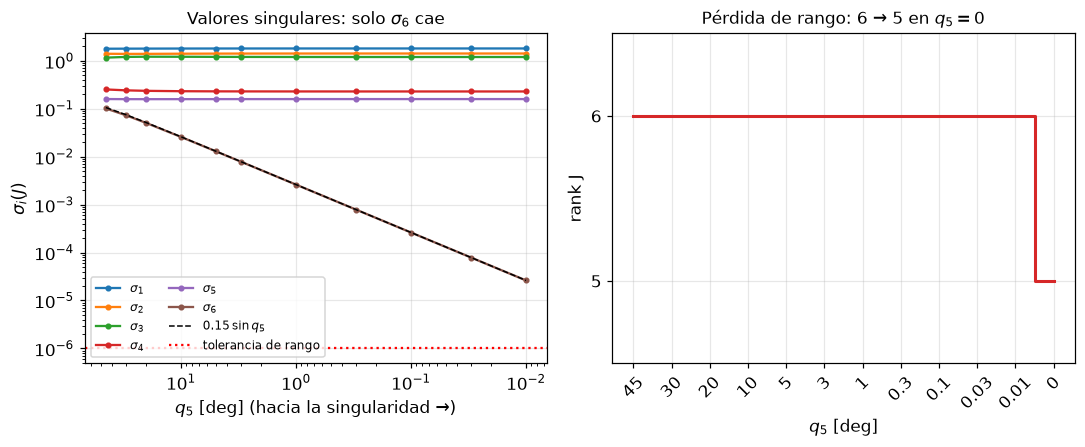

In [20]:
q5s = np.array([e["q5"] for e in EXP[:-1]])
S = np.array([e["ra"].singular_values for e in EXP[:-1]])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for i in range(6):
    axes[0].loglog(q5s, S[:, i], "o-", ms=3, label=fr"$\sigma_{i+1}$")
axes[0].loglog(q5s, 0.15 * np.sin(np.deg2rad(q5s)), "k--", lw=1, label=r"$0.15\,\sin q_5$")
axes[0].axhline(RANK_TOLERANCE, color="r", ls=":", label="tolerancia de rango")
axes[0].invert_xaxis(); axes[0].set_xlabel(r"$q_5$ [deg] (hacia la singularidad →)"); axes[0].set_ylabel(r"$\sigma_i(J)$")
axes[0].legend(ncol=2, fontsize=8); axes[0].set_title("Valores singulares: solo $\\sigma_6$ cae")
ranks = [e["ra"].rank for e in EXP]
axes[1].step(range(len(EXP)), ranks, where="mid", color="C3", lw=2)
axes[1].set_xticks(range(len(EXP)), [f"{v:g}" for v in Q5_SEQ_DEG], rotation=45)
axes[1].set_ylim(4.5, 6.5); axes[1].set_yticks([5, 6]); axes[1].set_xlabel(r"$q_5$ [deg]"); axes[1].set_ylabel("rank J")
axes[1].set_title("Pérdida de rango: 6 → 5 en $q_5 = 0$")
fig.tight_layout(); save(fig, "D_singularidad_rango"); plt.show()

### 7.1 ¿Qué movilidad se pierde?

En $q_5 = 0$, $z_5 = z_3$: los ejes 4 y 6 son **colineales**, así que dos motores producen la misma rotación. La SVD
da las dos direcciones que lo explican:

- $v_6$ (espacio nulo de $J$): un movimiento articular que **no mueve el TCP**.
- $u_6$ (complemento del rango): un twist que **ningún $\dot q$ puede producir**. Se expresa con el centro de muñeca
  $W$ como punto de referencia para que la parte angular no se mezcle con la palanca $W \to$ TCP.

In [21]:
sing = EXP[-1]
v_null = sing["ra"].null_joint_motions[:, 0]
# Para leer la rotación perdida se usa el centro de muñeca W como punto de referencia del twist:
# así la parte angular no se mezcla con la palanca W->TCP.
ra_w = rank_analysis(geometric_jacobian(sing["q"], "wrist"))
u_lost = ra_w.lost_twist_directions[:, 0]
frames = joint_frames(sing["q"])
z3, z4 = frames[3][:3, 2], frames[4][:3, 2]
axis_lost = np.cross(z3, z4) / np.linalg.norm(np.cross(z3, z4))
w_part = u_lost[3:] / np.linalg.norm(u_lost[3:])
print("Movimiento nulo v6 (q̇ normalizado):", v_null.round(4))
print("  -> q̇4 = -q̇6 y el brazo quieto: los dos motores giran opuestos y se cancelan.")
print("Twist perdido u6 = [v_W; ω] (referencia en W):", u_lost.round(4))
print("Parte angular de u6 (normalizada):", w_part.round(4), "  z3 × z4:", axis_lost.round(4))
print(f"|cos(ángulo)| entre ambas = {abs(w_part @ axis_lost):.6f}")
print("Twist del TCP con q̇ = v6:", (sing["J"] @ v_null).round(12))
check("D", "movimiento nulo: q̇4 = -q̇6 y q̇1..q̇3 = 0",
      np.allclose(v_null[:3], 0, atol=1e-9) and np.isclose(v_null[3], -v_null[5], atol=1e-9))
check("D", "la rotación perdida es alrededor de z3 × z4", abs(abs(w_part @ axis_lost) - 1) < 1e-9)

Movimiento nulo v6 (q̇ normalizado): [-0.     -0.      0.      0.7071 -0.     -0.7071]
  -> q̇4 = -q̇6 y el brazo quieto: los dos motores giran opuestos y se cancelan.
Twist perdido u6 = [v_W; ω] (referencia en W): [ 0.5658 -0.6587 -0.4413  0.0597 -0.1336  0.1727]
Parte angular de u6 (normalizada): [ 0.2636 -0.5901  0.7631]   z3 × z4: [ 0.2636 -0.5901  0.7631]
|cos(ángulo)| entre ambas = 1.000000
Twist del TCP con q̇ = v6: [-0. -0. -0. -0. -0. -0.]
  ✔ [D] movimiento nulo: q̇4 = -q̇6 y q̇1..q̇3 = 0
  ✔ [D] la rotación perdida es alrededor de z3 × z4


### 7.2 Amplificación de velocidad articular (y por qué NO implica torque infinito)

Para producir un twist unitario en la dirección más débil, $u_6$, hace falta $\dot q = J^{-1}u_6 = v_6/\sigma_6$, es
decir, $\lVert\dot q\rVert = 1/\sigma_6 \propto 1/\sin q_5$. Para saber si eso es físicamente posible, se compara
**junta por junta** con el datasheet: $\rho = \max_i |\dot q_i|/v_{\max,i}$. Si $\rho > 1$, al menos un motor
debería girar más rápido que su máximo.

En **estática**, en cambio, $\tau = J^T F$. Una fuerza o momento en esa misma dirección $u_6$ necesita
$\tau = J^T u_6 = \sigma_6\,v_6 \to 0$: **la estructura soporta esa carga sin torque de los motores**. La singularidad
amplifica velocidades, no torques. Un torque solo crece si se *exige* seguir una trayectoria cartesiana a través de
ella, porque entonces $\ddot q$ también explota.

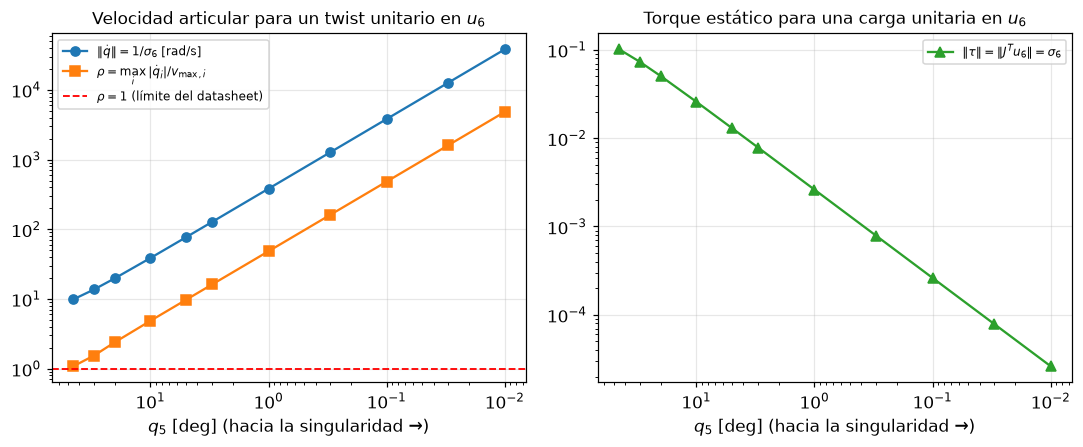

Pendiente log-log de ||q̇|| frente a sin(q5): -1.000  (teoría: -1)
 q5 [deg] ||q̇|| [rad/s]  q̇4 [rad/s]  q̇6 [rad/s]        rho
    30.00           13.7          8.6         -9.3        1.5
     1.00          382.7        270.8       -270.4       48.5
     0.10         3824.3       2704.4      -2704.0      484.2
     0.01        38240.5      27040.3     -27039.9     4841.6
Twist de magnitud 1 en u6: supera la velocidad máxima de algún eje (rho > 1) desde q5 ≈ 45.0°
Twist de magnitud 0.1 en u6: supera la velocidad máxima de algún eje (rho > 1) desde q5 ≈ 3.0°
  ✔ [D] amplificación ||q̇|| ∝ 1/sin(q5) (pendiente -1 ± 0.02)
  ✔ [D] torque estático en la dirección perdida tiende a 0


In [22]:
amp, ratio, tau_static, qd_unit = [], [], [], []
for e in EXP[:-1]:
    s6, u6, v6 = weakest_directions(e["J"])
    qd = np.linalg.solve(e["J"], u6)                      # q̇ para un twist unitario en u6
    qd_unit.append(qd)
    amp.append(np.linalg.norm(qd))
    ratio.append(np.max(np.abs(qd) / MAX_SPEED_RAD_S))     # comparación junta por junta con el datasheet
    tau_static.append(np.linalg.norm(e["J"].T @ u6))      # carga unitaria [F; M] en la dirección perdida
amp, ratio, tau_static = map(np.array, (amp, ratio, tau_static))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
axes[0].loglog(q5s, amp, "o-", label=r"$\|\dot q\| = 1/\sigma_6$ [rad/s]")
axes[0].loglog(q5s, ratio, "s-", label=r"$\rho = \max_i |\dot q_i|/v_{\max,i}$")
axes[0].axhline(1.0, color="r", ls="--", lw=1.2, label=r"$\rho = 1$ (límite del datasheet)")
axes[0].invert_xaxis(); axes[0].set_xlabel(r"$q_5$ [deg] (hacia la singularidad →)"); axes[0].legend(fontsize=8)
axes[0].set_title("Velocidad articular para un twist unitario en $u_6$")
axes[1].loglog(q5s, tau_static, "^-", color="C2", label=r"$\|\tau\| = \|J^T u_6\| = \sigma_6$")
axes[1].invert_xaxis(); axes[1].set_xlabel(r"$q_5$ [deg] (hacia la singularidad →)"); axes[1].legend(fontsize=8)
axes[1].set_title("Torque estático para una carga unitaria en $u_6$")
fig.tight_layout(); save(fig, "D_amplificacion"); plt.show()

slope = np.polyfit(np.log(np.sin(np.deg2rad(q5s[-5:]))), np.log(amp[-5:]), 1)[0]
print(f"Pendiente log-log de ||q̇|| frente a sin(q5): {slope:.3f}  (teoría: -1)")
print(f"{'q5 [deg]':>9} {'||q̇|| [rad/s]':>14} {'q̇4 [rad/s]':>12} {'q̇6 [rad/s]':>12} {'rho':>10}")
for e, a, r, qd in zip(EXP[:-1], amp, ratio, qd_unit):
    if e["q5"] in (30, 1, 0.1, 0.01):
        print(f"{e['q5']:9.2f} {a:14.1f} {qd[3]:12.1f} {qd[5]:12.1f} {r:10.1f}")
# rho es proporcional a la magnitud del twist pedido: se informa para 1 (unitario) y para 0.1 (p. ej. 10 cm/s)
for mag in (1.0, 0.1):
    bad = [e["q5"] for e, r in zip(EXP[:-1], ratio) if mag * r > 1]
    print(f"Twist de magnitud {mag:g} en u6: supera la velocidad máxima de algún eje (rho > 1) desde q5 ≈ {bad[0]}°"
          if bad else f"Twist de magnitud {mag:g}: nunca supera el datasheet en la secuencia")
AMP_QD_MAX, AMP_RATIO = np.max(np.abs(qd_unit[-1])), ratio[-1]
check("D", "amplificación ||q̇|| ∝ 1/sin(q5) (pendiente -1 ± 0.02)", abs(slope + 1) < 0.02)
check("D", "torque estático en la dirección perdida tiende a 0", tau_static[-1] < 1e-3 * tau_static[0])

### 7.3 Complemento: singularidad de codo (brazo estirado)

Mismo procedimiento acercando $q_3$ a $\delta - 90° = -76.95°$. Ahí $\cos(q_3 - \delta) = 0$, el centro de muñeca
está en el borde del alcance ($|SW| \to L_2 + L_3 = 0.580$ m) y se pierde la capacidad de alejar $W$ radialmente.

In [23]:
elbow_deg = np.rad2deg(DELTA - np.pi / 2)
offsets = np.array([20, 10, 5, 2, 1, 0.3, 0.1, 0.0])
print(f"q3 singular = δ - 90° = {elbow_deg:.3f}°")
print(f"{'q3 [deg]':>9} {'|S-W| [m]':>10} {'rango':>5} {'sigma_6':>10}")
elbow_ranks = []
for off in offsets:
    q_k = q_base.copy(); q_k[4] = np.deg2rad(40); q_k[2] = np.deg2rad(elbow_deg + off)
    ra = rank_analysis(geometric_jacobian(q_k))
    W = joint_frames(q_k)[4][:3, 3]
    print(f"{elbow_deg + off:9.3f} {np.linalg.norm(W - [0, 0, D1]):10.5f} {ra.rank:>5} {ra.singular_values[-1]:10.2e}")
    elbow_ranks.append(ra.rank)
check("D", "singularidad de codo: rango 5 con el brazo estirado y 6 fuera de ella",
      elbow_ranks[-1] == 5 and all(r == 6 for r in elbow_ranks[:-1]))

q3 singular = δ - 90° = -76.950°
 q3 [deg]  |S-W| [m] rango    sigma_6
  -56.950    0.57124     6   3.62e-02
  -66.950    0.57781     6   1.86e-02
  -71.950    0.57946     6   9.34e-03
  -74.950    0.57992     6   3.74e-03
  -75.950    0.57998     6   1.87e-03
  -76.650    0.58000     6   5.62e-04
  -76.850    0.58001     6   1.87e-04
  -76.950    0.58001     5   3.46e-18
  ✔ [D] singularidad de codo: rango 5 con el brazo estirado y 6 fuera de ella


## 8. Dinámica reducida 1R del hombro y torque $\tau(t)$ (criterio E)

**Modelo de clase.** $\theta$ se mide desde la vertical inferior. Con $T = \tfrac12 J\dot\theta^2$ y
$V = mg\ell_c(1 - \cos\theta)$, Euler-Lagrange da

$$
\tau = \underbrace{J\,\ddot\theta}_{\tau_{in}} + \underbrace{mg\ell_c\sin\theta}_{\tau_g}, \qquad J = I_c + m\ell_c^2
$$

$\dot\theta$ no aparece porque en este modelo 1R la inercia $J$ es **constante** (no depende de $\theta$): por eso no
hay un término cuadrático en la velocidad. Un sistema de una coordenada con inercia variable $M(q)$ sí tendría uno,
$\tfrac12 M'(q)\dot q^2$.

**Reducción del IRB 120 (supuestos):**

- El actuador es la **junta 2 (hombro)**, de eje horizontal, que carga los eslabones 2 a 6 y la pinza.
- Las juntas 3 a 6 se **congelan** en $q_{\text{ref}} = (q_0 + q_f)/2$ (postura media del movimiento), así que
  $\theta = q_2 + \varphi_0$ y $\ddot\theta = \ddot q_2$.
- $m$, $\ell_c$, $I_c$ y $\varphi_0$ se **calculan** con el CAD por eslabón de Truc y Lam (2020) más la pinza SMC
  (0.115 kg). No se inventa ningún valor.
- No se modelan fricción, carga útil ni el acople con las otras juntas.

In [24]:
MODEL = shoulder_model(0.5 * (Q0 + QF))
print(f"m = {MODEL.mass_kg:.3f} kg,  lc = {MODEL.lc_m:.4f} m,  Ic = {MODEL.inertia_com_kg_m2:.4f} kg m²,  "
      f"J = Ic + m lc² = {MODEL.inertia_kg_m2:.4f} kg m²")
print(f"phi0 = {deg(MODEL.phi0_rad):.3f}°  (theta = q2 + phi0),  m g lc = {MODEL.max_gravity_torque:.3f} N·m")

print("\nSensibilidad a la postura congelada de las juntas 3-6:")
for name, q_ref in (("q0", Q0), ("(q0+qf)/2", 0.5 * (Q0 + QF)), ("qf", QF)):
    m = shoulder_model(q_ref)
    print(f"  q_ref = {name:>10}: lc = {m.lc_m:.4f} m, J = {m.inertia_kg_m2:.4f} kg m², phi0 = {deg(m.phi0_rad):8.3f}°")

q_ref = np.array(MODEL.q_ref)
dJ = abs(MODEL.inertia_kg_m2 - dynamics.mass_matrix(q_ref)[1, 1])
dg = abs(float(MODEL.torque(q_ref[1], 0.0)) - dynamics.gravity_vector(q_ref)[1])
print(f"\nValidación contra el Lagrangiano completo de 6 GDL en q_ref: |J - M22| = {dJ:.1e},  |m g lc sinθ - g2| = {dg:.1e}")
check("E", "J = M22(q_ref) y τ_g = g2(q_ref) del modelo completo", dJ < 1e-9 and dg < 1e-9)

m = 12.210 kg,  lc = 0.2491 m,  Ic = 0.4479 kg m²,  J = Ic + m lc² = 1.2053 kg m²
phi0 = -163.815°  (theta = q2 + phi0),  m g lc = 29.832 N·m

Sensibilidad a la postura congelada de las juntas 3-6:
  q_ref =         q0: lc = 0.2420 m, J = 1.1486 kg m², phi0 = -161.924°
  q_ref =  (q0+qf)/2: lc = 0.2491 m, J = 1.2053 kg m², phi0 = -163.815°
  q_ref =         qf: lc = 0.2554 m, J = 1.2554 kg m², phi0 = -165.913°

Validación contra el Lagrangiano completo de 6 GDL en q_ref: |J - M22| = 0.0e+00,  |m g lc sinθ - g2| = 1.4e-14
  ✔ [E] J = M22(q_ref) y τ_g = g2(q_ref) del modelo completo


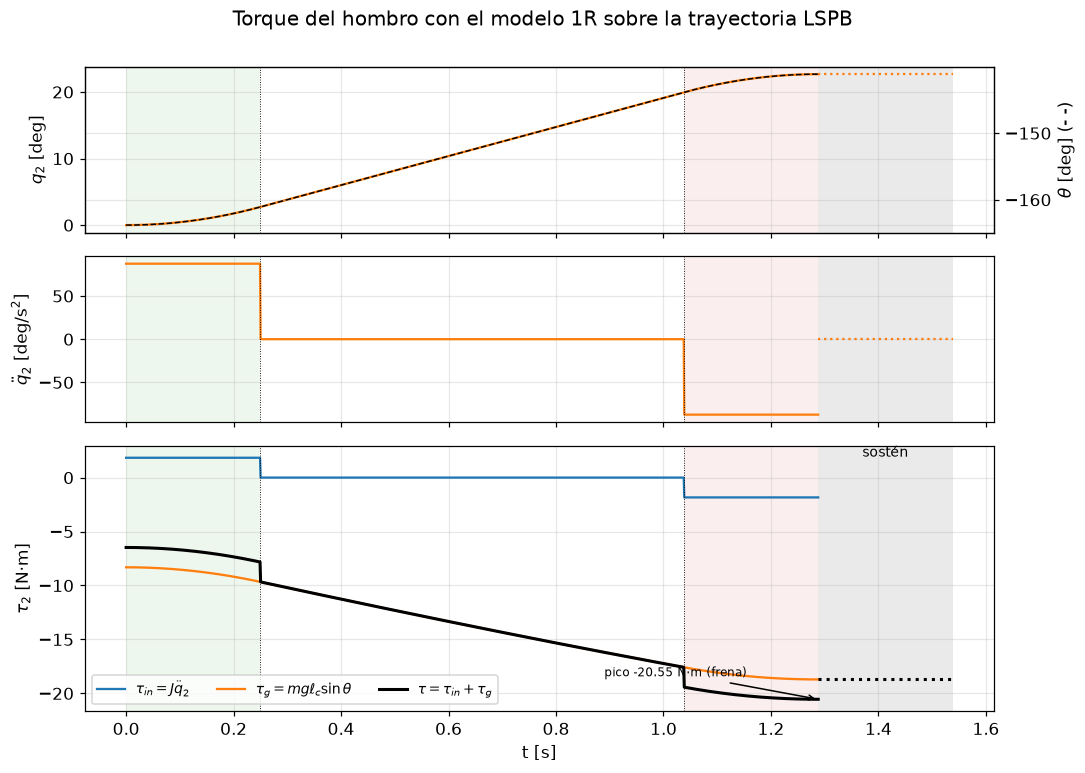

  instante     fase  q2 [deg] theta [deg]   tau_in     tau_g  tau [N m]
    0.0000  acelera     0.000    -163.815    1.838    -8.316     -6.478
    0.1250  acelera     0.682    -163.132    1.838    -8.656     -6.819
    0.6440  crucero    11.333    -152.481    0.000   -13.784    -13.784
    1.1629    frena    21.984    -141.830   -1.838   -18.436    -20.274
    1.2879    frena    22.667    -141.148   -1.838   -18.714    -20.552
Al terminar: en t_f⁻ (último instante del frenado) τ = -20.552 N·m; en t_f⁺ (robot detenido, q̈ = 0) τ = τ_g = -18.714 N·m: el motor deja de frenar pero sigue sosteniendo el brazo.

Pico |τ| = 20.552 N·m en t = 1.288 s (frena)
|τ_in| máx = 1.838 N·m   |τ_g| máx = 18.714 N·m
En crucero: τ_in = 0, pero |τ| va de 9.67 a 17.58 N·m
  ✔ [E] en crucero τ_in = 0 pero τ ≠ 0 (velocidad constante no implica torque cero)


In [25]:
TAU_IN, TAU_G, TAU = MODEL.torque_components(Q_T[:, 1], QDD_T[:, 1])
THETA = MODEL.pendulum_angle(Q_T[:, 1])

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [1, 1, 1.6]})
axes[0].plot(T_GRID, deg(Q_T[:, 1]), color=JOINT_COLORS[1], label="$q_2$")
axes[0].set_ylabel("$q_2$ [deg]")
ax0b = axes[0].twinx(); ax0b.plot(T_GRID, deg(THETA), "k--", lw=1); ax0b.set_ylabel(r"$\theta$ [deg] (- -)")
axes[1].plot(T_GRID, deg(QDD_T[:, 1]), color=JOINT_COLORS[1]); axes[1].set_ylabel(r"$\ddot q_2$ [deg/s$^2$]")
axes[2].plot(T_GRID, TAU_IN, label=r"$\tau_{in} = J\ddot q_2$")
axes[2].plot(T_GRID, TAU_G, label=r"$\tau_g = m g \ell_c \sin\theta$")
axes[2].plot(T_GRID, TAU, "k", lw=2, label=r"$\tau = \tau_{in} + \tau_g$")
T_H = np.linspace(TRAJ.tf, TRAJ.tf + 0.25, 30)            # 0.25 s de sostén con el robot ya detenido
axes[0].plot(T_H, np.full_like(T_H, deg(QF[1])), color=JOINT_COLORS[1], ls=":")
axes[1].plot(T_H, np.zeros_like(T_H), color=JOINT_COLORS[1], ls=":")
axes[2].plot(T_H, np.full_like(T_H, float(MODEL.torque(QF[1], 0.0))), "k:", lw=2)
for ax in axes:
    ax.axvspan(TRAJ.tf, TRAJ.tf + 0.25, color="0.8", alpha=0.4, lw=0)
axes[2].text(TRAJ.tf + 0.125, axes[2].get_ylim()[1], "sostén", ha="center", va="top", fontsize=9)
k_peak = int(np.argmax(np.abs(TAU)))
axes[2].annotate(f"pico {TAU[k_peak]:.2f} N·m ({TRAJ.phase(T_GRID[k_peak])})", (T_GRID[k_peak], TAU[k_peak]),
                 xytext=(-140, 15), textcoords="offset points", fontsize=8, arrowprops=dict(arrowstyle="->"))
axes[2].set_ylabel(r"$\tau_2$ [N·m]"); axes[2].set_xlabel("t [s]"); axes[2].legend(ncol=3, loc="best")
for ax in axes: mark_phases(ax)
fig.suptitle("Torque del hombro con el modelo 1R sobre la trayectoria LSPB", y=1.0)
fig.tight_layout(); save(fig, "E_torque_1R"); plt.show()

print(f"{'instante':>10} {'fase':>8} {'q2 [deg]':>9} {'theta [deg]':>11} {'tau_in':>8} {'tau_g':>9} {'tau [N m]':>10}")
for t in (0.0, TRAJ.tb / 2, TRAJ.tf / 2, TRAJ.tf - TRAJ.tb / 2, TRAJ.tf):
    q, qd, qdd = TRAJ.sample(t)
    ti, tg, tt = MODEL.torque_components(q[1], qdd[1])
    print(f"{t:10.4f} {TRAJ.phase(t):>8} {deg(q[1]):9.3f} {deg(MODEL.pendulum_angle(q[1])):11.3f} "
          f"{float(ti):8.3f} {float(tg):9.3f} {float(tt):10.3f}")
cruise = np.array([TRAJ.phase(t) == "crucero" for t in T_GRID])
TAU_HOLD = float(MODEL.torque(QF[1], 0.0))     # robot ya detenido en qf: solo gravedad
print(f"Al terminar: en t_f⁻ (último instante del frenado) τ = {TAU[-1]:.3f} N·m; en t_f⁺ (robot detenido, q̈ = 0) "
      f"τ = τ_g = {TAU_HOLD:.3f} N·m: el motor deja de frenar pero sigue sosteniendo el brazo.")
print(f"\nPico |τ| = {abs(TAU[k_peak]):.3f} N·m en t = {T_GRID[k_peak]:.3f} s ({TRAJ.phase(T_GRID[k_peak])})")
print(f"|τ_in| máx = {np.abs(TAU_IN).max():.3f} N·m   |τ_g| máx = {np.abs(TAU_G).max():.3f} N·m")
if cruise.any():
    print(f"En crucero: τ_in = 0, pero |τ| va de {np.abs(TAU[cruise]).min():.2f} a {np.abs(TAU[cruise]).max():.2f} N·m")
    check("E", "en crucero τ_in = 0 pero τ ≠ 0 (velocidad constante no implica torque cero)",
          np.abs(TAU_IN[cruise]).max() < 1e-12 and np.abs(TAU[cruise]).min() > 1e-3)
else:
    print("Perfil triangular: no hay tramo de velocidad constante. Aun así, en t = t_f (reposo) "
          f"τ = τ_g = {float(MODEL.torque(QF[1], 0.0)):.2f} N·m ≠ 0: sostener el brazo exige torque.")

**Interpretación de $\tau(t)$.**

- **$\tau_g$** depende solo de la **posición**: es máximo cuando el centro de masa queda horizontal
  ($\theta = \pm90°$) y nulo cuando queda vertical. En el IRB 120, $\theta$ suele estar cerca de $\pm180°$: el centro
  de masa queda por encima del hombro y el brazo trabaja como un **péndulo invertido**. Cuanto más se inclina,
  mayor es $|\sin\theta|$ y mayor el esfuerzo para sostenerlo.
- **$\tau_{in}$** es un escalón $\pm J a_2$ en las fases de mezcla y **cero en crucero**. Sus discontinuidades vienen
  de que $\ddot q$ del LSPB es discontinua.
- **Velocidad constante no implica torque cero:** en crucero $\ddot q = 0$, pero el motor sigue sosteniendo el peso.
- **El pico de esfuerzo** aparece donde $\tau_{in}$ y $\tau_g$ tienen el mismo signo; donde tienen signos opuestos,
  el torque neto es menor que el estático. La celda anterior indica en qué fase cae el pico para la pose dada.
- Al 25 % de velocidad **domina la gravedad**: $|\tau_{in}|$ es una fracción pequeña de $|\tau_g|$.

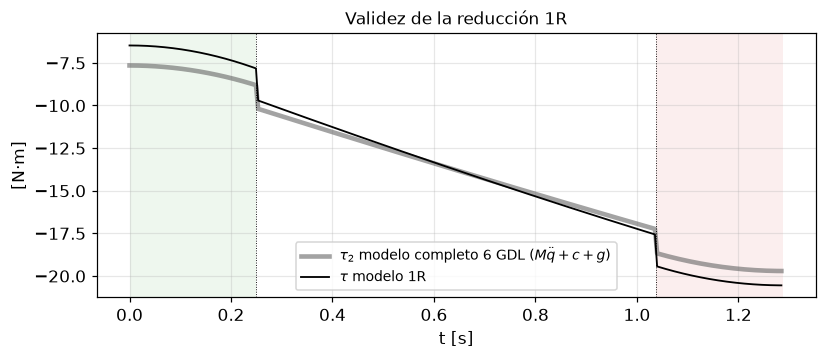

Error RMS 1R frente al completo: 0.637 N·m (4.5 % del RMS de τ2); máx 1.174 N·m
→ La reducción 1R es una buena aproximación para este movimiento (error RMS < 15 %).


In [26]:
# Validación de la aproximación: 1R frente al tau_2 del modelo completo (todas las juntas moviéndose)
sub = slice(None, None, 4)
TAU_FULL = np.array([dynamics.inverse_dynamics(q, qd, qdd)[1] for q, qd, qdd in zip(Q_T[sub], QD_T[sub], QDD_T[sub])])
err = TAU[sub] - TAU_FULL
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(T_GRID[sub], TAU_FULL, color="0.4", lw=3, alpha=0.6, label=r"$\tau_2$ modelo completo 6 GDL ($M\ddot q + c + g$)")
ax.plot(T_GRID[sub], TAU[sub], "k", lw=1.2, label=r"$\tau$ modelo 1R")
mark_phases(ax); ax.set_xlabel("t [s]"); ax.set_ylabel("[N·m]"); ax.legend()
ax.set_title("Validez de la reducción 1R")
fig.tight_layout(); save(fig, "E_1R_vs_completo"); plt.show()
rms_ref = np.sqrt(np.mean(TAU_FULL**2))
rms = np.sqrt(np.mean(err**2))
print(f"Error RMS 1R frente al completo: {rms:.3f} N·m ({100 * rms / rms_ref:.1f} % del RMS de τ2); máx {np.abs(err).max():.3f} N·m")
if rms < 0.15 * rms_ref:
    print("→ La reducción 1R es una buena aproximación para este movimiento (error RMS < 15 %).")
else:
    print("→ ATENCIÓN: error RMS ≥ 15 %. Las juntas 3-6 se mueven mucho en este movimiento y el supuesto de\n"
          "  'cuerpo congelado' pierde validez; el modelo completo es la referencia (discutirlo en el informe).")

**Alcance de esta validación.** Las dos curvas usan los **mismos parámetros CAD**, así que la comparación mide cuánto
se pierde al **reducir** el modelo, no cuánto se parece al robot real (no hay mediciones de torque en hardware). La
diferencia se debe a lo que el 1R deja fuera: mientras el hombro se mueve, las juntas 3 a 6 también se mueven
(cambian $\ell_c$ y $J$), y aparecen acoplamientos inerciales y de Coriolis entre juntas. Como el 1R usa la postura
media, el error es mayor al principio y al final, donde la postura real se aleja más de $q_{\text{ref}}$.

**Efecto de la velocidad.** Se recorre la misma trayectoria $\lambda$ veces más rápido ($t \to t/\lambda$). Entonces
$\ddot q \to \lambda^2\ddot q$: $\tau_{in}$ crece con $\lambda^2$, mientras que $\tau_g$ no cambia porque depende solo
de la posición. (Escalas por encima del 25 % pueden superar el $a_{\max}$ supuesto; aquí solo se ilustra la
tendencia.)

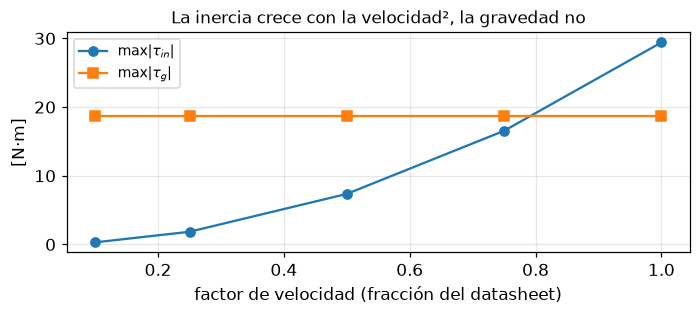

  escala 0.10: max|τ_in| =  0.294 N·m, max|τ_g| = 18.714 N·m
  escala 0.25: max|τ_in| =  1.838 N·m, max|τ_g| = 18.714 N·m
  escala 0.50: max|τ_in| =  7.351 N·m, max|τ_g| = 18.714 N·m
  escala 0.75: max|τ_in| = 16.539 N·m, max|τ_g| = 18.714 N·m
  escala 1.00: max|τ_in| = 29.403 N·m, max|τ_g| = 18.714 N·m
  ✔ [E] τ_g no depende de la velocidad y τ_in escala con el cuadrado de la velocidad


In [27]:
from irb120.lspb import LspbTrajectory
scales = np.array([0.1, 0.25, 0.5, 0.75, 1.0])     # fracción de la velocidad del datasheet
peak_in, peak_g = [], []
for s in scales:
    lam = s / SPEED_SCALE                            # misma geometría recorrida lam veces más rápido
    tr = LspbTrajectory(Q0, QF, TRAJ.tf / lam, TRAJ.tb / lam)
    tt = np.linspace(0, tr.tf, 800); q, qd, qdd = tr.sample_many(tt)
    ti, tg, _ = MODEL.torque_components(q[:, 1], qdd[:, 1])
    peak_in.append(np.abs(ti).max()); peak_g.append(np.abs(tg).max())
peak_in, peak_g = np.array(peak_in), np.array(peak_g)
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(scales, peak_in, "o-", label=r"$\max|\tau_{in}|$"); ax.plot(scales, peak_g, "s-", label=r"$\max|\tau_g|$")
ax.set_xlabel("factor de velocidad (fracción del datasheet)"); ax.set_ylabel("[N·m]"); ax.legend()
ax.set_title("La inercia crece con la velocidad², la gravedad no")
fig.tight_layout(); save(fig, "E_efecto_velocidad"); plt.show()
for s, a, b in zip(scales, peak_in, peak_g):
    print(f"  escala {s:4.2f}: max|τ_in| = {a:6.3f} N·m, max|τ_g| = {b:6.3f} N·m")
check("E", "τ_g no depende de la velocidad y τ_in escala con el cuadrado de la velocidad",
      np.ptp(peak_g) < 1e-9 and np.allclose(peak_in, np.abs(TAU_IN).max() * (scales / SPEED_SCALE) ** 2))

## 9. Discusión, resumen de verificaciones y conclusiones

### 9.1 Singularidad cinemática frente a esfuerzo dinámico

| | Singularidad (sección 7) | Pico de torque (sección 8) |
|---|---|---|
| Naturaleza | Cinemática: geometría de $J(q)$ | Dinámica: inercia × aceleración + gravedad |
| Criterio | $\operatorname{rank}J < 6$ (SVD) | $\lvert\tau\rvert$ frente a la capacidad del actuador |
| Depende de | Solo de la postura $q$ | De $q$ y del perfil temporal $\ddot q$ |
| Qué diverge | $\dot q$ necesaria para ciertos $\dot x$ ($\propto 1/\sin q_5$) | Nada diverge: $\tau$ es acotado si $\ddot q$ lo es |
| Torque estático en la dirección perdida | $\to 0$ ($J^T u_6 = \sigma_6 v_6$) | — |
| ¿Se evita bajando la velocidad? | No: depende de la postura | En parte: baja $\tau_{in}$, pero $\tau_g$ se mantiene |

La trayectoria **parte de** una singularidad (la pose inicial tiene $q_5 = 0$) y aun así el torque del hombro en ese
instante es moderado, porque el LSPB es articular. La celda siguiente muestra en qué fase y con qué rango de $J$
ocurre el pico de $\tau(t)$: la singularidad y el pico de torque son fenómenos independientes.

In [28]:
print(f"{'etapa':>6}  verificación")
for stage, desc, ok in CHECKS:
    print(f"{stage:>6}  {'✔' if ok else '✘'} {desc}")
print(f"\n{sum(ok for *_, ok in CHECKS)}/{len(CHECKS)} verificaciones aprobadas")
print(f"\nResumen: pose objetivo {np.round(T_D[:3, 3], 4)} m -> rama {chosen.branch} "
      f"({chosen.arm}/{chosen.elbow}/{chosen.wrist}), qf = {deg(QF).round(3)} deg")
print(f"LSPB: t_f = {TRAJ.tf:.4f} s, t_b = {TRAJ.tb:.4f} s;  pico |τ2| (1R) = {abs(TAU[k_peak]):.3f} N·m")
print(f"Pico de torque en t = {T_GRID[k_peak]:.3f} s, fase '{TRAJ.phase(T_GRID[k_peak])}', rango J = {RANK_T[k_peak]} "
      f"(sigma_min = {SV_T[k_peak, -1]:.3f});  en t = 0: rango J = {RANK_T[0]}, |τ| = {abs(TAU[0]):.2f} N·m")
print(f"Figuras guardadas en: {FIG_DIR}")

 etapa  verificación
Modelo  ✔ FK(q=0) reproduce la geometría del datasheet
     A  ✔ pose Inicial: se enumeran las 8 ramas
     A  ✔ pose Objetivo: se enumeran las 8 ramas
     A  ✔ Pieper recupera la posición de calibración q = 0 a partir de T_0
     A  ✔ la pose objetivo es alcanzable (al menos una rama admisible)
     B  ✔ las 16 ramas reales reproducen su pose (posición y orientación) bajo tolerancia
     B  ✔ se rechaza el candidato con error en q1 = 1e-3 rad
     B  ✔ se rechaza el candidato con error solo en q6 = 1e-2 rad
     B  ✔ ida y vuelta: 1000/1000 poses resueltas y q original recuperado
     B  ✔ la FK por DH coincide con el modelo OFICIAL de ROS-Industrial (pose completa, < 1e-9)
     B  ✔ la FK por DH coincide con el URDF del Hito 1 (implementación, < 1e-9)
     A  ✔ se evaluaron las 8 ramas y se eligió exactamente una
     A  ✔ la configuración elegida es admisible y reproduce T_d
     C  ✔ q(0) = q0 y q(tf) = qf (error 0.0e+00)
     C  ✔ reposo en las fronteras: q̇(

### 9.2 Exportación de resultados para el informe IEEE

El informe (`docs/hito2/informe_ieee/`) **no copia números a mano**: lee de la carpeta `resultados/` los valores y
las tablas que escribe esta celda. Si cambia la pose objetivo, basta con volver a ejecutar el notebook y recompilar
el PDF.

In [29]:
RES_DIR = ROOT / "resultados"
RES_DIR.mkdir(exist_ok=True)

def sci(x, digits=1):
    # 2.2e-16 -> 2.2\times10^{-16} (para modo matemático de LaTeX)
    mant, exp = f"{x:.{digits}e}".split("e")
    return rf"{mant}\times10^{{{int(exp)}}}"

def z(v, nd=2):
    # redondea y quita el signo de -0.00
    return f"{round(float(v), nd) + 0.0:.{nd}f}"

def fmt_q(q):
    return ", ".join(f"{v + 0.0:.2f}" for v in np.round(deg(q), 2))   # + 0.0 evita "-0.00"

obj = REPORTS["Objetivo"]
pos = T_D[:3, 3]
rpy = spec[3:] if spec.shape == (6,) else matrix_to_rpy_deg(T_D[:3, :3])   # la entrada del docente tal cual
D_obj = obj.shoulder_to_wrist_m
c_obj = (D_obj**2 - L2**2 - L3**2) / (2 * L2 * L3)
k_cr = int(np.argmax(np.maximum(np.abs(QF - Q0) / VMAX, np.abs(QF - Q0) / AMAX)))
cruise_txt = (f"{np.abs(TAU[cruise]).min():.1f} a {np.abs(TAU[cruise]).max():.1f}" if cruise.any() else "---")
values = {
    "PoseObjPos": f"({pos[0]:.2f}, {pos[1]:.2f}, {pos[2]:.2f})",
    "PoseObjRPY": f"({rpy[0]:.1f}^\\circ, {rpy[1]:.1f}^\\circ, {rpy[2]:.1f}^\\circ)",
    "PWObj": "({:.3f}, {:.3f}, {:.3f})".format(*obj.wrist_center),
    "DObj": f"{D_obj:.4f}", "CObj": f"{c_obj:.3f}",
    "NReales": str(sum(c.real for c in obj.candidates)), "NAdm": str(len(obj.admissible)),
    "RamaSel": str(chosen.branch), "RamaSelTxt": f"{chosen.arm}/{chosen.elbow}/{chosen.wrist}",
    "QfDeg": fmt_q(QF),
    "MaxEp": sci(max(r[2] for r in rows)), "MaxEr": sci(max(r[3] for r in rows)), "NRamasReales": str(len(rows)),
    "RTEp": sci(stats.max_position_error_m), "RTEr": sci(stats.max_rotation_error_rad),
    "Tf": f"{TRAJ.tf:.4f}", "Tb": f"{TRAJ.tb:.4f}", "JuntaCritica": str(k_cr + 1),
    "SaltoMax": sci(max(LCHK.position_jump, LCHK.velocity_jump)),
    "ErrJ": sci(diff), "ErrV": sci(err_v), "SigmaMinQf": f"{rank_analysis(J).singular_values[-1]:.3f}",
    "RangoQf": str(rank_analysis(J).rank),
    "Masa": f"{MODEL.mass_kg:.3f}", "Lc": f"{MODEL.lc_m:.4f}", "Ic": f"{MODEL.inertia_com_kg_m2:.4f}",
    "Jsh": f"{MODEL.inertia_kg_m2:.4f}", "PhiZero": f"{deg(MODEL.phi0_rad):.2f}",
    "MGLc": f"{MODEL.max_gravity_torque:.2f}", "ErrModelo": sci(max(dJ, dg)),
    "TauPeak": f"{TAU[k_peak]:.2f}", "TauPeakT": f"{T_GRID[k_peak]:.3f}", "TauPeakFase": TRAJ.phase(T_GRID[k_peak]),
    "TauIni": f"{TAU[0]:.2f}", "TauInMax": f"{np.abs(TAU_IN).max():.2f}", "TauGMax": f"{np.abs(TAU_G).max():.2f}",
    "CruceroRango": cruise_txt,
    "RMS": f"{rms:.2f}", "RMSPct": f"{100 * rms / rms_ref:.1f}", "ErrMax": f"{np.abs(err).max():.2f}",
    "TauInFull": f"{peak_in[-1]:.1f}", "TauGFull": f"{peak_g[-1]:.1f}",
    "TauSosten": f"{TAU_HOLD:.2f}",
    "AmpQdMax": f"{AMP_QD_MAX:.0f}", "AmpRatio": f"{AMP_RATIO:.0f}",
    "MargenQf": f"{best.limit_margin_deg:.1f}", "CostoQf": f"{best.weighted_cost:.3f}",
    "NAptas": str(sum(d.rank is not None for d in DECISIONS)),
    "NChecks": str(len(CHECKS)),
}
with open(RES_DIR / "valores.tex", "w") as f:
    f.write("% Generado por Hito2_IRB120_pipeline.ipynb -- no editar a mano\n")
    for key, val in values.items():
        f.write(f"\\newcommand{{\\{key}}}{{{val}}}\n")

short = {"frente": "fr", "atras": "at", "arriba": "arr", "abajo": "ab", "q5+": "$+$", "q5-": "$-$"}
with open(RES_DIR / "tabla_ramas.tex", "w") as f:
    for row in obj.table():
        name = f"{short[row['brazo']]}/{short[row['codo']]}/{short[row['muneca']]}"
        state = "admisible" if row["aceptada"] else ("no real" if not row["real"] else "J" + ",".join(map(str, row["fuera_de_limites"])))
        qs = " & ".join(f"${v + 0.0:.2f}$" for v in np.round(row["q_deg"], 2)) if row["q_deg"] else r"\multicolumn{6}{c}{no existe ($|c|>1$)}"
        line = f"{row['rama']} & {name} & {qs} & {state}"
        f.write((r"\rowcolor{black!8} " if row["aceptada"] and row["rama"] == chosen.branch else "") + line + r"\\" + "\n")
with open(RES_DIR / "tabla_lspb.tex", "w") as f:
    for j in range(6):
        f.write(f"{j+1} & ${z(deg(D[j]))}$ & ${z(deg(TRAJ.cruise_velocity[j]))}$ & ${z(deg(TRAJ.blend_acceleration[j]))}$ & "
                f"{z(abs(TRAJ.cruise_velocity[j]) / VMAX[j])} & {z(abs(TRAJ.blend_acceleration[j]) / AMAX[j])}\\\\\n")
with open(RES_DIR / "tabla_torque.tex", "w") as f:
    for label, t, t_eval in (("0", 0.0, 0.0), ("", TRAJ.tf / 2, TRAJ.tf / 2), ("", TRAJ.tf - TRAJ.tb / 2, TRAJ.tf - TRAJ.tb / 2),
                             ("^-", TRAJ.tf, TRAJ.tf), ("^+", TRAJ.tf, TRAJ.tf + 1e-9)):
        q, qd, qdd = TRAJ.sample(t_eval)
        ti, tg, tt = MODEL.torque_components(q[1], qdd[1])
        tlabel = f"$t_f{label}$" if label in ("^-", "^+") else f"{t:.3f}"
        f.write(f"{tlabel} & {TRAJ.phase(t_eval)} & ${z(deg(MODEL.pendulum_angle(q[1])), 1)}$ & ${z(ti)}$ & "
                f"${z(tg)}$ & ${z(tt)}$\\\\\n")
print("Escrito en", RES_DIR, ":", sorted(p.name for p in RES_DIR.iterdir()))

Escrito en /home/marcelo767/Documentos/robotica/robotica-IMT342/2-2026/IMT342/equipo/proyecto/hito2/resultados : ['tabla_lspb.tex', 'tabla_ramas.tex', 'tabla_torque.tex', 'valores.tex']


### 9.3 Conclusiones

1. **Pieper (A).** Para la pose inicial (posición de calibración ABB) y para la pose objetivo se enumeran de forma
   analítica las 8 ramas, y cada una se clasifica como real, en límites y admisible. Pieper recupera exactamente
   $q = 0$ desde la pose inicial, aunque sea una singularidad de muñeca.
2. **Validación (B).** Todas las ramas reales reproducen su pose con errores del orden de $10^{-16}$, y el criterio
   rechaza candidatos con errores solo de orientación. La prueba de ida y vuelta recupera el 100 % de 1000
   configuraciones aleatorias.
3. **LSPB (C).** Perfil sincronizado de tiempo mínimo entre las dos poses, con límites del datasheet y un supuesto de
   aceleración declarado. Se verifican las fronteras en reposo, la continuidad de $q$ y $\dot q$ y el respeto de los
   límites.
4. **Jacobiano y singularidad (D).** $J$ se valida contra derivadas numéricas y columnas hechas a mano. El experimento
   independiente muestra la caída de rango 6 → 5, la movilidad perdida (rotación sobre $z_3 \times z_4$ y el
   movimiento interno $\dot q_4 = -\dot q_6$) y la amplificación $\lVert\dot q\rVert \propto 1/\sin q_5$, sin torque
   infinito.
5. **Dinámica (E).** El modelo 1R del hombro, con parámetros del CAD, coincide exactamente con el modelo completo en
   la postura de referencia y lo aproxima bien a lo largo del movimiento. La gravedad domina y la inercia aparece
   solo en las mezclas: velocidad constante no implica torque cero.